# 02 — Data Preprocessing | NYC 311 (2023–2025)



**Input:** `data/processed/selected_modeling_features.csv` generated from the  2023–2025 dataset by `src.features.select_modeling_features`.

**Goal:** inspect and transform selected ZIP/borough-area features, compare scaling methods, and save **baseline** and **group-balanced** input matrices for PCA and K-Means.

1. Inspect distributions, outliers and correlations.
2. Apply a small, explicit set of log transformations.
3. Compare StandardScaler and RobustScaler (diagnostic only).
4. Construct a grouped-feature baseline using standardization and square-root category shares.
5. Build an experimental equal-variance group-balanced matrix.
6. Save matrices, preprocessing artifacts, quality reports and validate their integrity.

**Scope:** The raw complaint records have already been cleaned and aggregated. This notebook operates on **area-level features**, not individual complaints. Spatial DBSCAN uses its own geographic processing pipeline.

**No fixed row or feature count is assumed.** The actual counts come from the regenerated full-data selected-features file. Run the notebook from top to bottom after feature selection succeeds.

In [1]:
import sys
import logging
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when VS Code/Jupyter starts in project root or notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "config" / "config.py").is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find project root containing config/config.py. "
        "Open the Urban Infrastructure Pulse Intelligence project in VS Code."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.config import PROCESSED_DATA_DIR, OUTPUT_DIR

INPUT_FILE = PROCESSED_DATA_DIR / "selected_modeling_features.csv"
PREPROCESSING_OUTPUT_DIR = OUTPUT_DIR / "tables" / "preprocessing"
FIGURE_DIR = OUTPUT_DIR / "figures" / "preprocessing"
PREPROCESSING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
logger = logging.getLogger("data_preprocessing")
print("Project root:", PROJECT_ROOT)
print("Input:", INPUT_FILE)
print("Preprocessing reports:", PREPROCESSING_OUTPUT_DIR)


Project root: d:\Urban-Infrastructure-Pulse-Intelligence
Input: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\selected_modeling_features.csv
Preprocessing reports: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\preprocessing


In [2]:
if not INPUT_FILE.is_file():
    raise FileNotFoundError(
        f"Selected modeling dataset not found: {INPUT_FILE}\n"
        "First run: python -m src.features.select_modeling_features"
    )

df = pd.read_csv(INPUT_FILE, low_memory=False)
if df.empty:
    raise ValueError("Selected modeling dataset is empty.")
if "area_id" not in df.columns:
    raise ValueError("area_id column missing from selected modeling dataset.")
if df["area_id"].isna().any() or df["area_id"].duplicated().any():
    raise ValueError("Missing or duplicate area_id values found.")

non_numeric = df.drop(columns=["area_id"]).select_dtypes(exclude="number").columns.tolist()
if non_numeric:
    raise TypeError(f"Non-numeric modeling columns: {non_numeric}")
if not np.isfinite(df.drop(columns=["area_id"]).to_numpy(dtype=float)).all():
    raise ValueError("Missing or infinite numerical values found.")

share_columns_input = sorted(c for c in df.columns if c.startswith("share_"))
if not share_columns_input:
    raise ValueError("No share_* infrastructure-composition features found.")
if not np.allclose(df[share_columns_input].sum(axis=1), 1.0, atol=1e-5, rtol=0):
    raise ValueError(
        "Selected category shares do not sum to 1. "
        "Review dropped constant shares and run the feature-selection validation."
    )

logger.info("Loaded %d geographic areas, %d selected numerical features", len(df), df.shape[1]-1)
print("Composition categories:", len(share_columns_input))
display(df.head())


INFO: Loaded 238 geographic areas, 20 selected numerical features


Composition categories: 14


,area_id,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,...,share_sidewalk_condition,share_street_condition,share_street_light_condition,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance
0,BRONX_10451,3144,36,0.196180,0.739186,0.501590,775.731803,0.015267,0.006043,0.071565,...,0.073791,0.268766,0.213104,0.017176,0.013677,0.020674,0.284987,0.000000,0.010814,0.001590
1,BRONX_10452,3107,36,0.251985,0.704538,0.451883,721.342271,0.017702,0.009334,0.094947,...,0.141294,0.265529,0.183135,0.020921,0.013840,0.016736,0.214677,0.000322,0.019633,0.000966
2,BRONX_10453,3031,36,0.302023,0.713626,0.452986,722.286601,0.014847,0.017156,0.095018,...,0.088090,0.235896,0.204553,0.015836,0.013857,0.019136,0.270538,0.000000,0.022765,0.001980
3,BRONX_10454,2484,36,0.278644,0.729469,0.443639,746.359956,0.008052,0.014090,0.080918,...,0.107488,0.283011,0.201288,0.015700,0.013688,0.014493,0.248390,0.000000,0.008857,0.003221
4,BRONX_10455,2387,36,0.183045,0.757436,0.506912,749.575947,0.018852,0.021366,0.087558,...,0.085463,0.204860,0.208211,0.009636,0.009636,0.019271,0.317553,0.000000,0.012987,0.002933


In [3]:
print("DATASET INFORMATION")
print("=" * 50)
print("Geographic areas:", df.shape[0])
print("Numerical modeling features:", df.shape[1] - 1)
print("Category-share features:", len(share_columns_input))
print("Duplicate area IDs:", int(df["area_id"].duplicated().sum()))
print("\nColumns:", df.columns.tolist())
display(df.dtypes.to_frame("Data Type"))
print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing Values").query("`Missing Values` > 0"))


DATASET INFORMATION
Geographic areas: 238
Numerical modeling features: 20
Category-share features: 14
Duplicate area IDs: 0

Columns: ['area_id', 'total_complaints', 'active_months', 'monthly_cv', 'repeated_complaint_rate', 'persistent_complaint_rate', 'avg_recurrence_span_days', 'share_curb_condition', 'share_root_sewer_sidewalk_condition', 'share_sewer', 'share_sewer_maintenance', 'share_sidewalk_condition', 'share_street_condition', 'share_street_light_condition', 'share_street_sign_-_damaged', 'share_street_sign_-_dangling', 'share_street_sign_-_missing', 'share_traffic_signal_condition', 'share_water_drainage', 'share_water_leak', 'share_water_maintenance']


,Data Type
area_id,str
total_complaints,int64
active_months,int64
monthly_cv,float64
repeated_complaint_rate,float64
persistent_complaint_rate,float64
avg_recurrence_span_days,float64
share_curb_condition,float64
share_root_sewer_sidewalk_condition,float64
share_sewer,float64



Missing values by column:


,Missing Values


## 2. Numerical Feature Distribution Analysis

This section examines the statistical properties of selected modeling features.

We will investigate:
- Mean and median
- Standard deviation
- Minimum and maximum values
- Skewness
- Zero values
- Potential outliers

The purpose is to identify appropriate preprocessing techniques before clustering.

In [4]:
# Identify numerical features
numeric_features = df.select_dtypes(
    include=[np.number]
).columns.tolist()

# Exclude geographic identifier if numeric in future datasets
numeric_features = [
    col for col in numeric_features
    if col != "area_id"
]

# Generate descriptive statistics
descriptive_stats = df[numeric_features].describe().T

# Add skewness
descriptive_stats["skewness"] = df[
    numeric_features
].skew()

# Add median
descriptive_stats["median"] = df[
    numeric_features
].median()

# Add zero count
descriptive_stats["zero_count"] = (
    df[numeric_features] == 0
).sum()

# Display results
display(
    descriptive_stats.round(4)
)

print("Total numerical features:", len(numeric_features))

,count,mean,std,min,25%,50%,75%,max,skewness,median,zero_count
total_complaints,238.0,2808.5714,2354.6457,1.000,163.7500,2811.0000,4345.2500,10646.0000,0.5816,2811.0000,0
active_months,238.0,29.4034,12.3239,1.000,34.5000,36.0000,36.0000,36.0000,-1.4715,36.0000,0
monthly_cv,238.0,0.9056,1.3940,0.134,0.2087,0.2570,0.6980,6.0000,2.3937,0.2570,0
repeated_complaint_rate,238.0,0.6085,0.2039,0.000,0.5982,0.6507,0.6939,1.0000,-1.7693,0.6507,17
persistent_complaint_rate,238.0,0.3108,0.1887,0.000,0.2473,0.3348,0.4114,0.9483,0.1781,0.3348,43
avg_recurrence_span_days,238.0,570.8725,275.5331,0.000,625.9069,672.6809,718.4047,941.8194,-1.4751,672.6809,43
share_curb_condition,238.0,0.0279,0.0431,0.000,0.0099,0.0201,0.0342,0.5000,7.2689,0.0201,47
share_root_sewer_sidewalk_condition,238.0,0.0333,0.0395,0.000,0.0011,0.0206,0.0543,0.3333,2.5191,0.0206,59
share_sewer,238.0,0.1036,0.0771,0.000,0.0553,0.0993,0.1462,0.5000,1.1854,0.0993,36
share_sewer_maintenance,238.0,0.0034,0.0070,0.000,0.0000,0.0016,0.0041,0.0909,8.6385,0.0016,68


Total numerical features: 20


In [5]:
skewness = df[numeric_features].skew()

skewness_report = pd.DataFrame({
    "feature": skewness.index,
    "skewness": skewness.values
})

skewness_report["skew_category"] = np.select(
    [
        skewness_report["skewness"].abs() <= 0.5,
        skewness_report["skewness"].abs() <= 1.0
    ],
    [
        "Approximately symmetric",
        "Moderately skewed"
    ],
    default="Highly skewed"
)

skewness_report = skewness_report.sort_values(
    "skewness",
    key=abs,
    ascending=False
)

display(skewness_report)

,feature,skewness,skew_category
15,share_street_sign_-_missing,9.879560,Highly skewed
9,share_sewer_maintenance,8.638542,Highly skewed
14,share_street_sign_-_dangling,8.099321,Highly skewed
6,share_curb_condition,7.268903,Highly skewed
13,share_street_sign_-_damaged,7.042976,Highly skewed
10,share_sidewalk_condition,3.965996,Highly skewed
17,share_water_drainage,3.891824,Highly skewed
12,share_street_light_condition,3.693138,Highly skewed
7,share_root_sewer_sidewalk_condition,2.519072,Highly skewed
18,share_water_leak,2.465567,Highly skewed


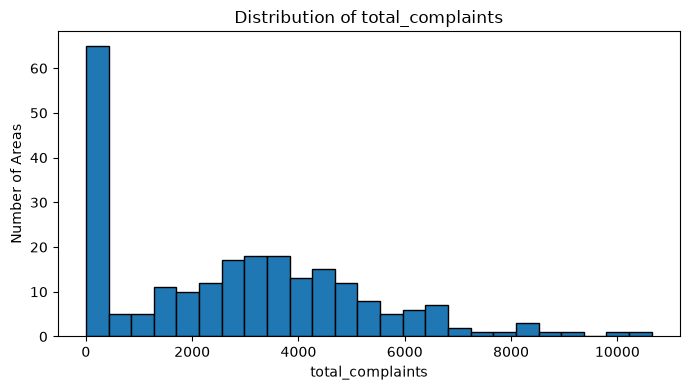

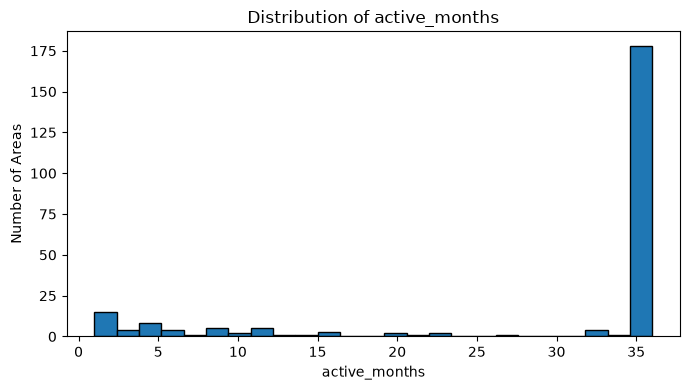

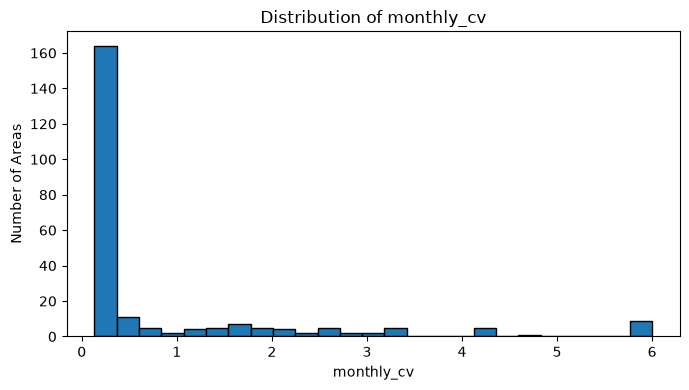

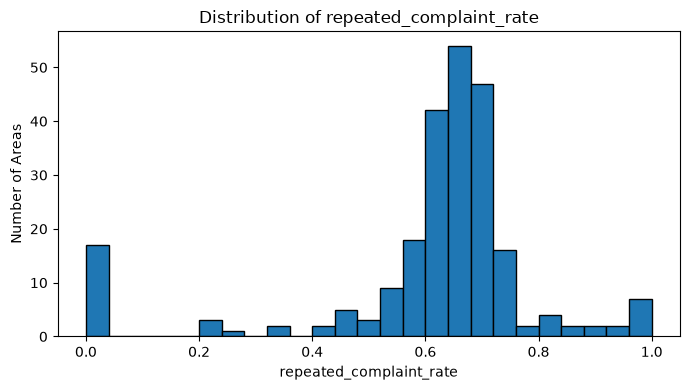

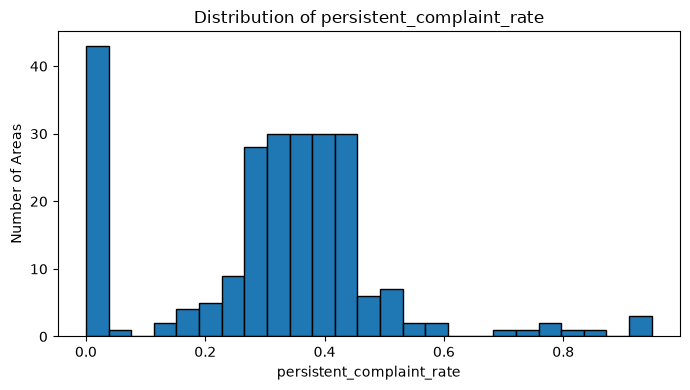

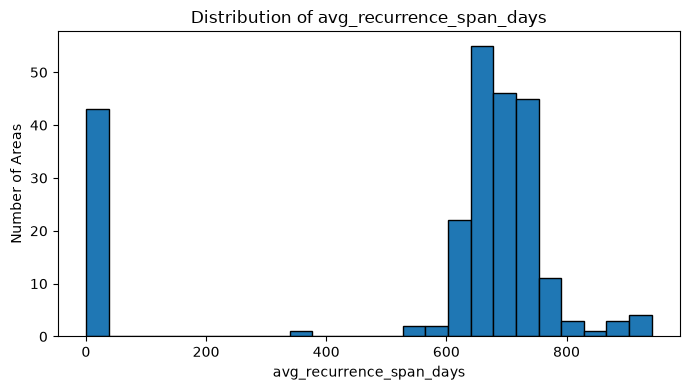

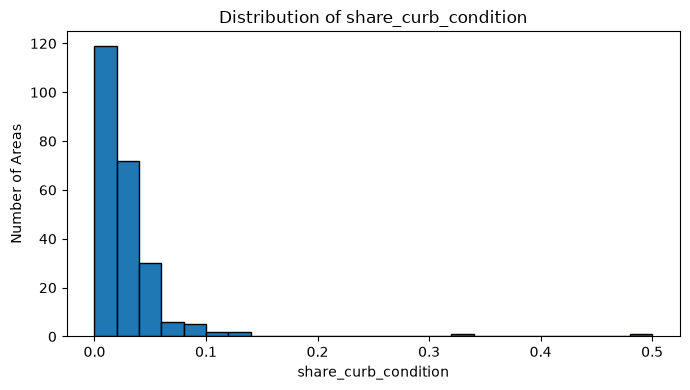

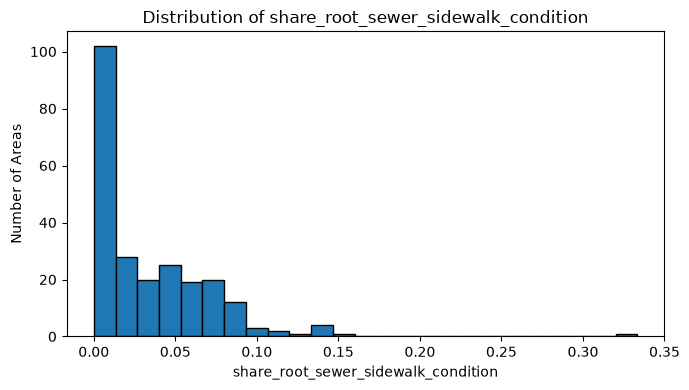

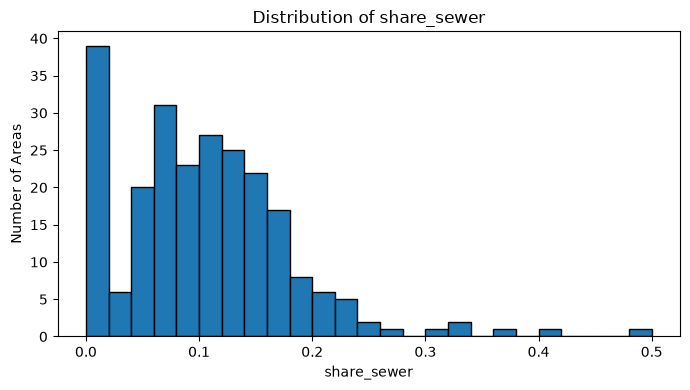

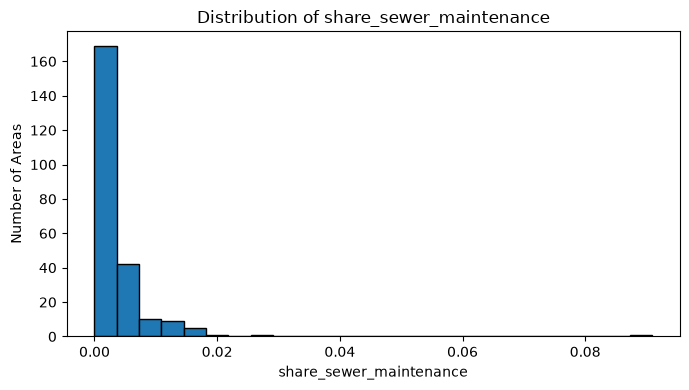

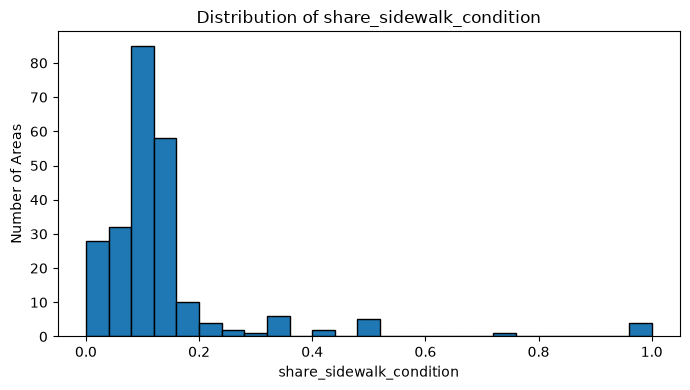

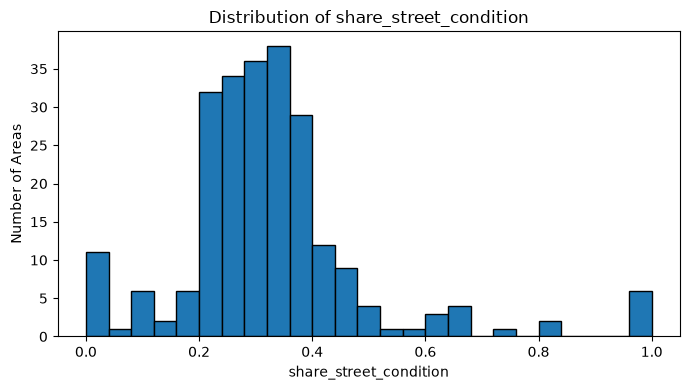

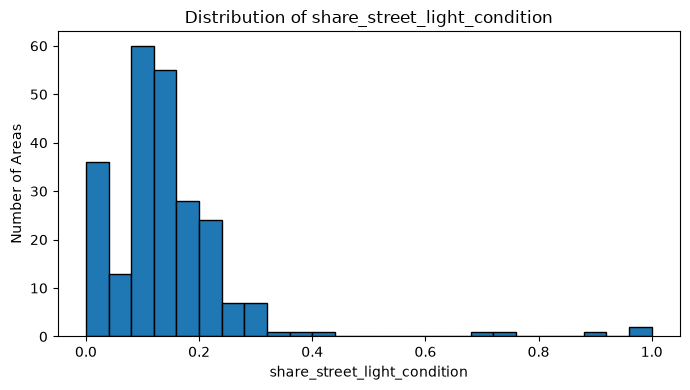

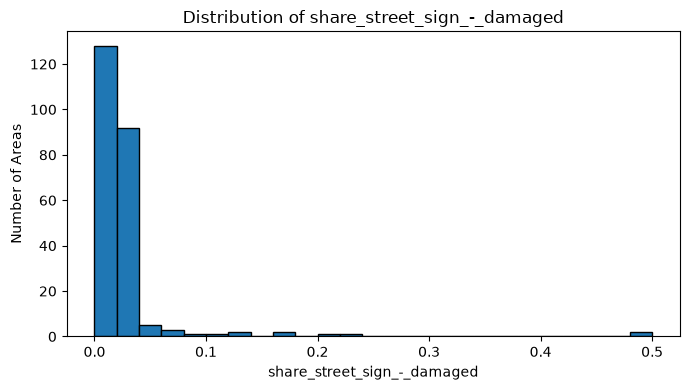

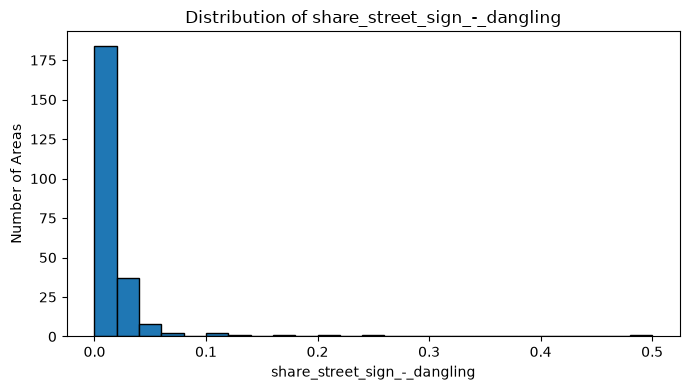

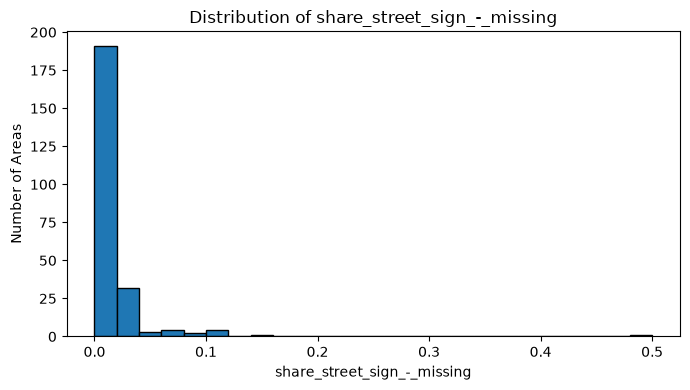

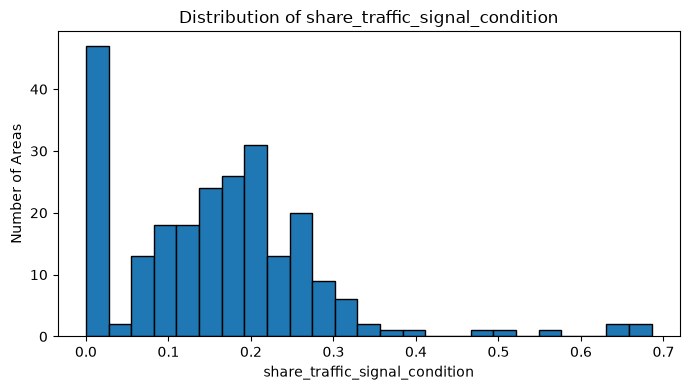

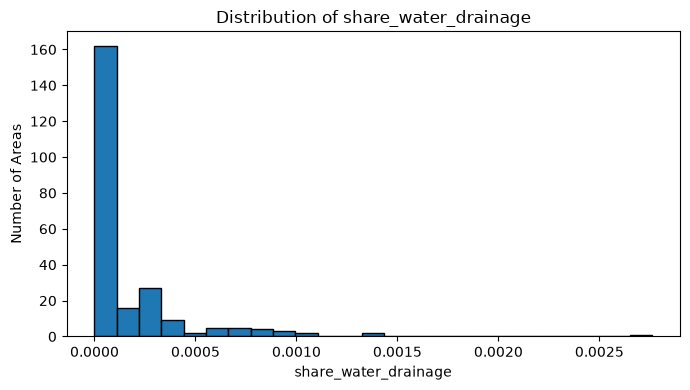

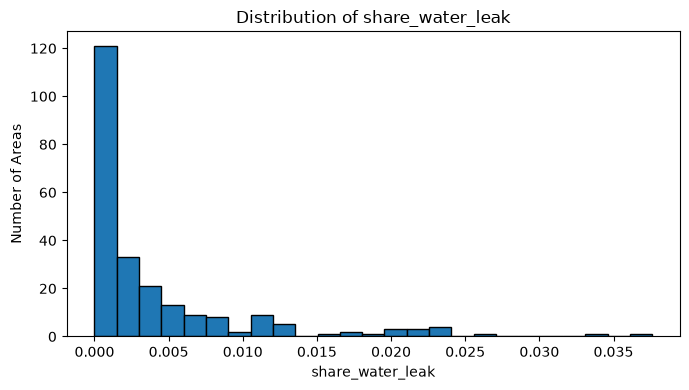

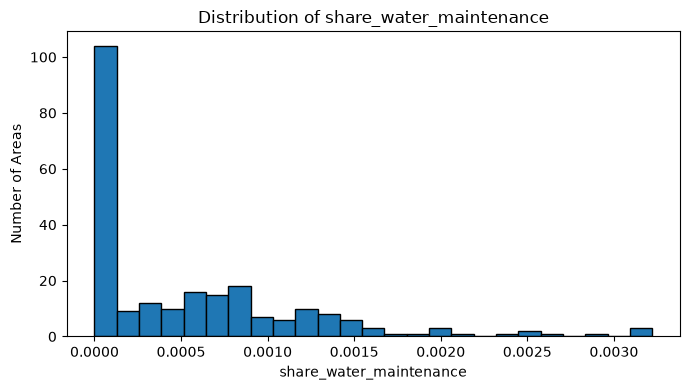

In [6]:
# Histograms for numerical features
for feature in numeric_features:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df[feature],
        bins=25,
        edgecolor="black"
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Areas")

    plt.tight_layout()
    plt.show()

Outlier Detection

C:\Users\Administrator\AppData\Local\Temp\ipykernel_11308\310871037.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11308\310871037.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11308\310871037.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11308\310871037.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxpl

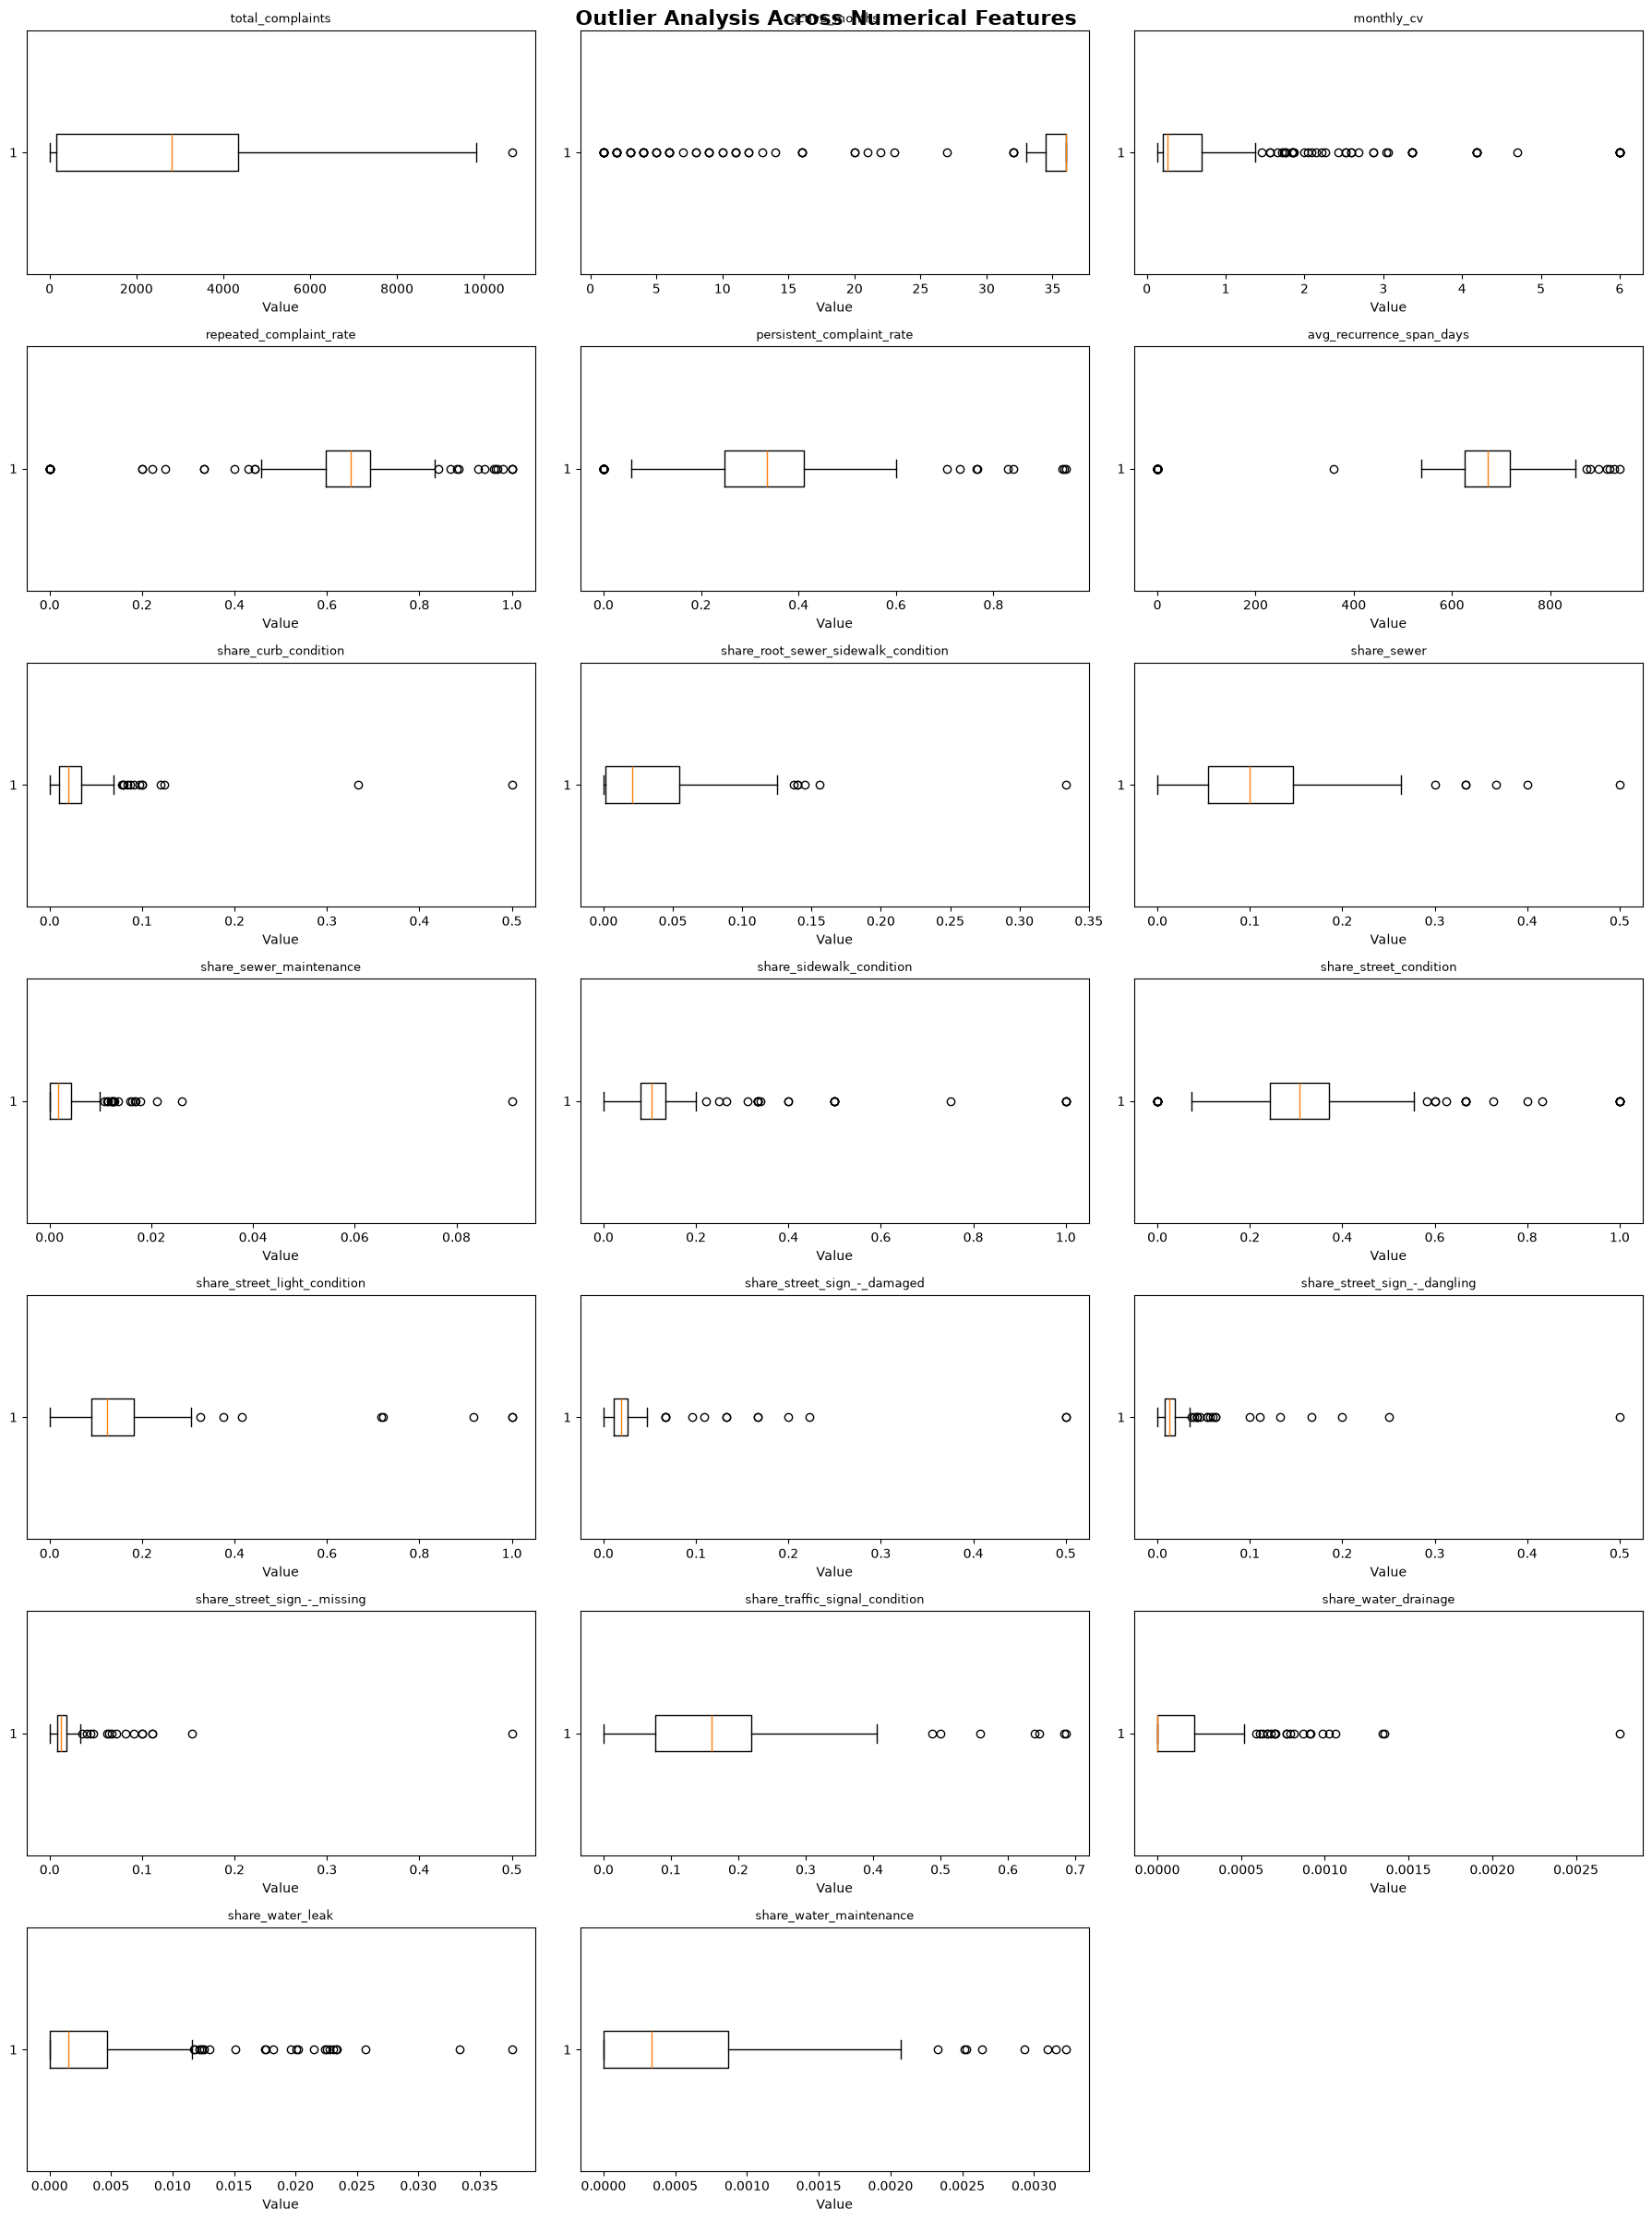

In [7]:
# Display multiple boxplots on one canvas

features_to_plot = numeric_features

n_cols = 3
n_rows = int(np.ceil(len(features_to_plot) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, feature in enumerate(features_to_plot):

    axes[i].boxplot(
        df[feature].dropna(),
        vert=False
    )

    axes[i].set_title(feature, fontsize=9)
    axes[i].set_xlabel("Value")

# Remove unused axes
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Outlier Analysis Across Numerical Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [8]:
outlier_results = []

for feature in numeric_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    outlier_results.append({
        "feature": feature,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": (
            outlier_count / len(df)
        ) * 100
    })

outlier_report = pd.DataFrame(outlier_results)

outlier_report = outlier_report.sort_values(
    "outlier_percentage",
    ascending=False
)

display(outlier_report.round(3))

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
1,active_months,32.250,38.250,58,24.370
4,persistent_complaint_rate,0.001,0.658,52,21.849
5,avg_recurrence_span_days,487.160,857.151,51,21.429
2,monthly_cv,-0.525,1.432,48,20.168
3,repeated_complaint_rate,0.455,0.838,40,16.807
11,share_street_condition,0.050,0.565,28,11.765
18,share_water_leak,-0.007,0.012,24,10.084
17,share_water_drainage,-0.000,0.001,22,9.244
10,share_sidewalk_condition,-0.000,0.213,22,9.244
14,share_street_sign_-_dangling,-0.009,0.036,19,7.983


Investigate zero-inflated features

In [9]:
# Identify features with zero values

zero_analysis = pd.DataFrame({
    "feature": numeric_features,
    "zero_count": [
        (df[col] == 0).sum()
        for col in numeric_features
    ]
})

zero_analysis["zero_percentage"] = (
    zero_analysis["zero_count"] / len(df)
) * 100

zero_analysis = zero_analysis.sort_values(
    "zero_percentage",
    ascending=False
)

display(zero_analysis.round(2))

,feature,zero_count,zero_percentage
17,share_water_drainage,160,67.23
19,share_water_maintenance,102,42.86
18,share_water_leak,79,33.19
9,share_sewer_maintenance,68,28.57
7,share_root_sewer_sidewalk_condition,59,24.79
14,share_street_sign_-_dangling,47,19.75
6,share_curb_condition,47,19.75
15,share_street_sign_-_missing,46,19.33
16,share_traffic_signal_condition,46,19.33
5,avg_recurrence_span_days,43,18.07


The following zero/non-zero plot is saved by the next code cell to `outputs/figures/preprocessing/`. It is diagnostic only; no features are removed here.

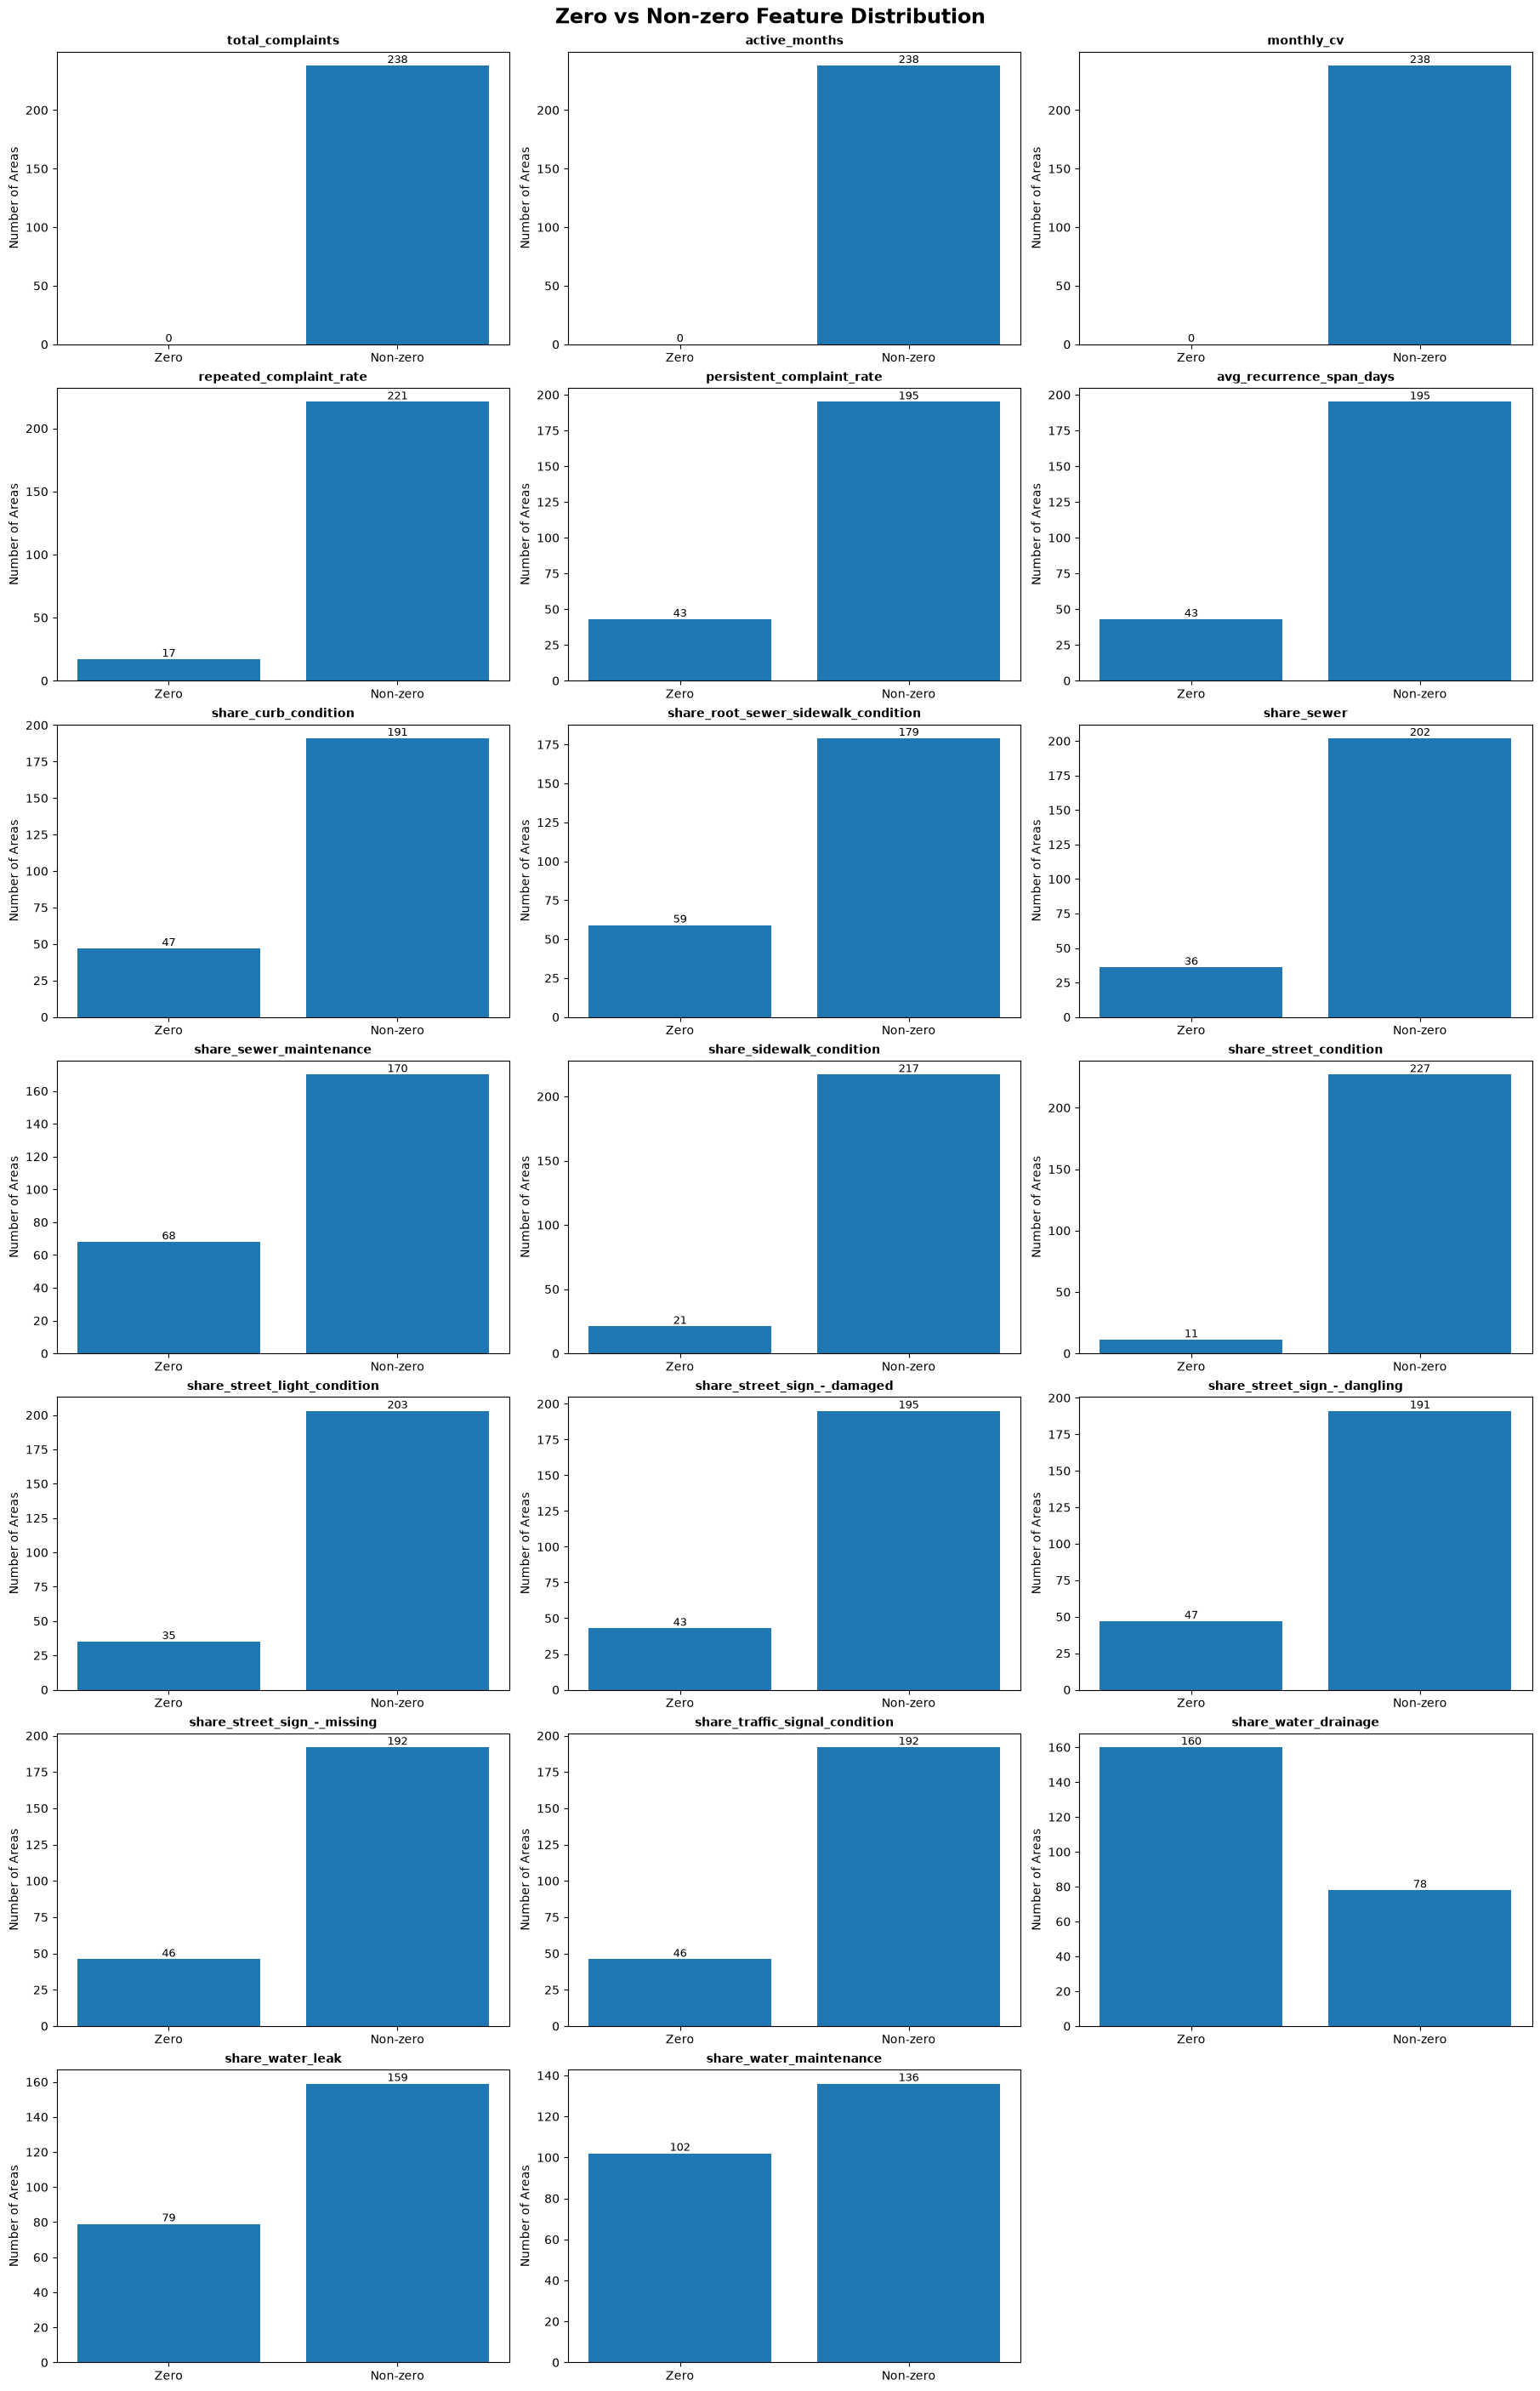

In [10]:
import math
import matplotlib.pyplot as plt

# Select numerical features
numeric_features = df.select_dtypes(include="number").columns.tolist()

n_features = len(numeric_features)
n_cols = 3
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows),
    constrained_layout=True
)

axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    zero_count = (df[feature] == 0).sum()
    nonzero_count = (df[feature] != 0).sum()

    axes[i].bar(
        ["Zero", "Non-zero"],
        [zero_count, nonzero_count]
    )

    axes[i].set_title(feature, fontsize=10, fontweight="bold")
    axes[i].set_ylabel("Number of Areas")
    axes[i].tick_params(axis="x", labelrotation=0)

    # Display values above bars
    for j, value in enumerate([zero_count, nonzero_count]):
        axes[i].text(j, value, str(value),
                     ha="center", va="bottom", fontsize=9)

# Remove unused subplot spaces
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Zero vs Non-zero Feature Distribution",
    fontsize=17,
    fontweight="bold"
)

plt.savefig(
    FIGURE_DIR / "zero_vs_nonzero_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Feature Correlation Analysis

,Feature 1,Feature 2,Correlation,Absolute Correlation
22,active_months,monthly_cv,-0.916443,0.916443
25,active_months,avg_recurrence_span_days,0.899897,0.899897


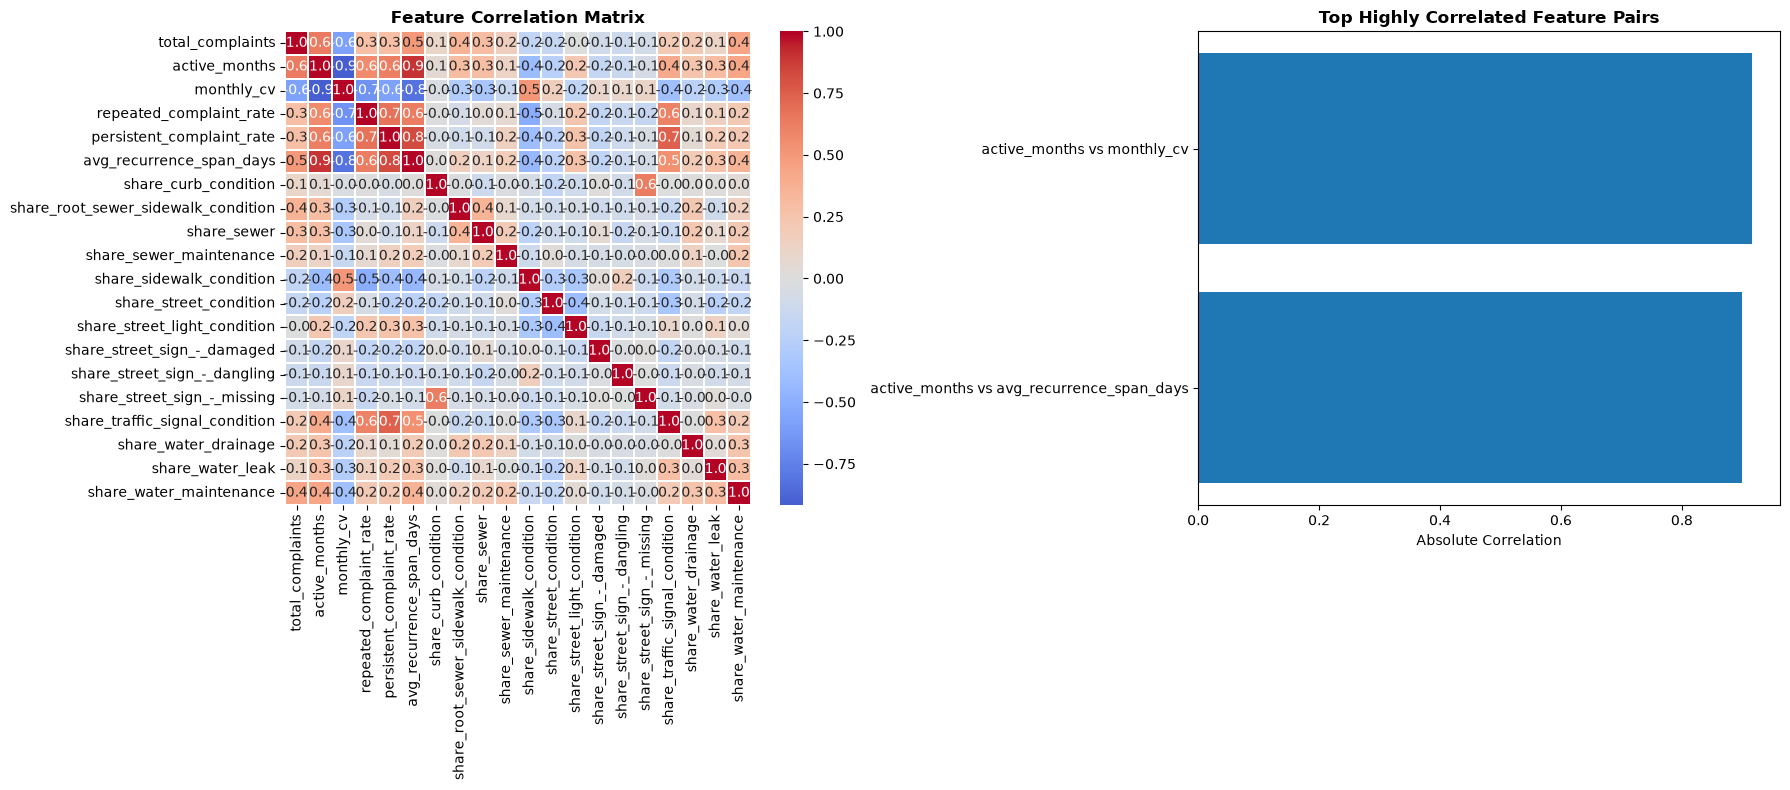

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Select numerical features
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Identify highly correlated feature pairs
correlation_pairs = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

high_correlations = correlation_pairs[
    correlation_pairs["Absolute Correlation"] >= 0.85
].sort_values("Absolute Correlation", ascending=False)

# Display results
display(high_correlations)

# Create a two-panel visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Panel 1: Correlation heatmap
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    ax=axes[0]
)

axes[0].set_title("Feature Correlation Matrix", fontweight="bold")

# Panel 2: Highly correlated feature pairs
top_pairs = (high_correlations if not high_correlations.empty else correlation_pairs.sort_values("Absolute Correlation", ascending=False)).head(15).copy()

top_pairs["Pair"] = (
    top_pairs["Feature 1"] + " vs " + top_pairs["Feature 2"]
)

axes[1].barh(
    top_pairs["Pair"],
    top_pairs["Absolute Correlation"]
)

axes[1].set_title(
    "Top Highly Correlated Feature Pairs",
    fontweight="bold"
)

axes[1].set_xlabel("Absolute Correlation")
axes[1].invert_yaxis()

plt.tight_layout()

# Save output
output_dir = FIGURE_DIR

plt.savefig(
    output_dir / "feature_correlation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Investigation of Highly Correlated Features

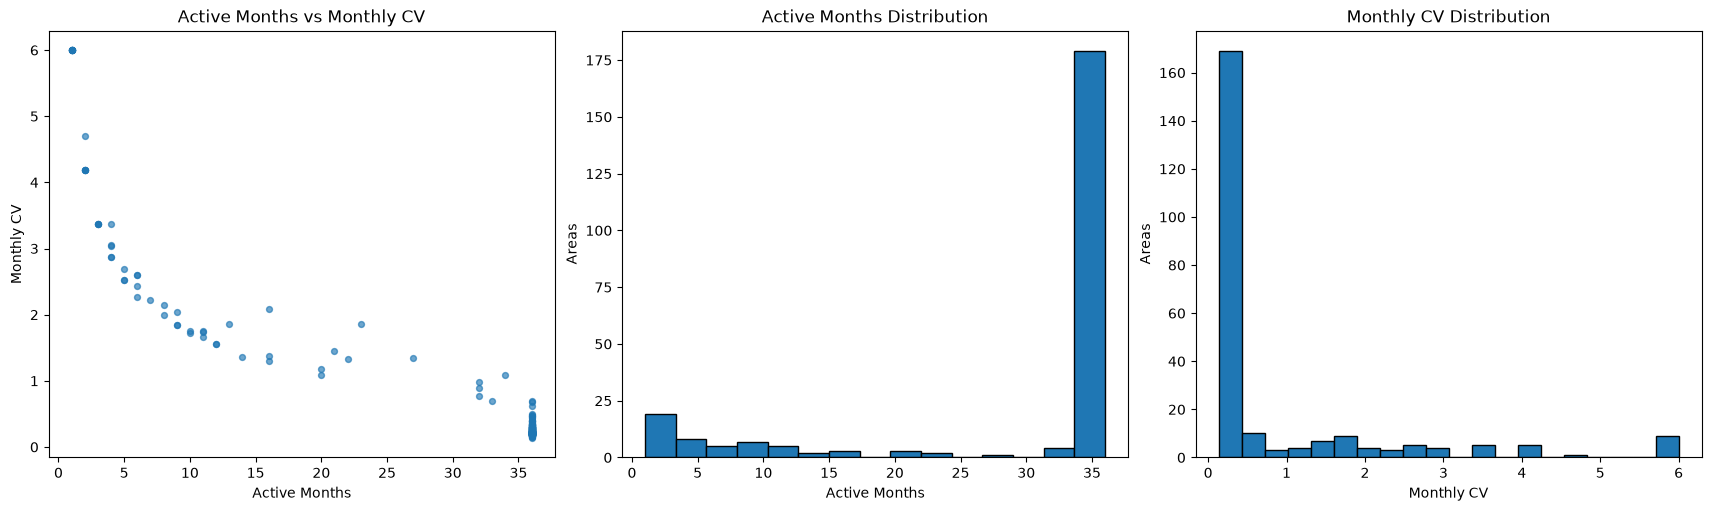

Active months / monthly CV correlation: -0.9164432076974923


In [12]:
# Matplotlib-only diagnostic for compatibility across seaborn versions.
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
axes[0].scatter(df["active_months"], df["monthly_cv"], alpha=0.65, s=18)
axes[0].set(title="Active Months vs Monthly CV", xlabel="Active Months", ylabel="Monthly CV")
axes[1].hist(df["active_months"], bins=15, edgecolor="black")
axes[1].set(title="Active Months Distribution", xlabel="Active Months", ylabel="Areas")
axes[2].hist(df["monthly_cv"], bins=20, edgecolor="black")
axes[2].set(title="Monthly CV Distribution", xlabel="Monthly CV", ylabel="Areas")
fig.savefig(FIGURE_DIR / "correlated_feature_investigation.png", dpi=200, bbox_inches="tight")
plt.show()
print("Active months / monthly CV correlation:", df["active_months"].corr(df["monthly_cv"]))


### Interpreting temporal correlations

Use the correlation value and plots above to decide whether `active_months` adds distinct information beyond `monthly_cv`. The relationship may differ from the previous 100K run. The baseline matrix below excludes `active_months` to reduce redundancy, but keeps this choice explicit for sensitivity tests.

Feature Transformation

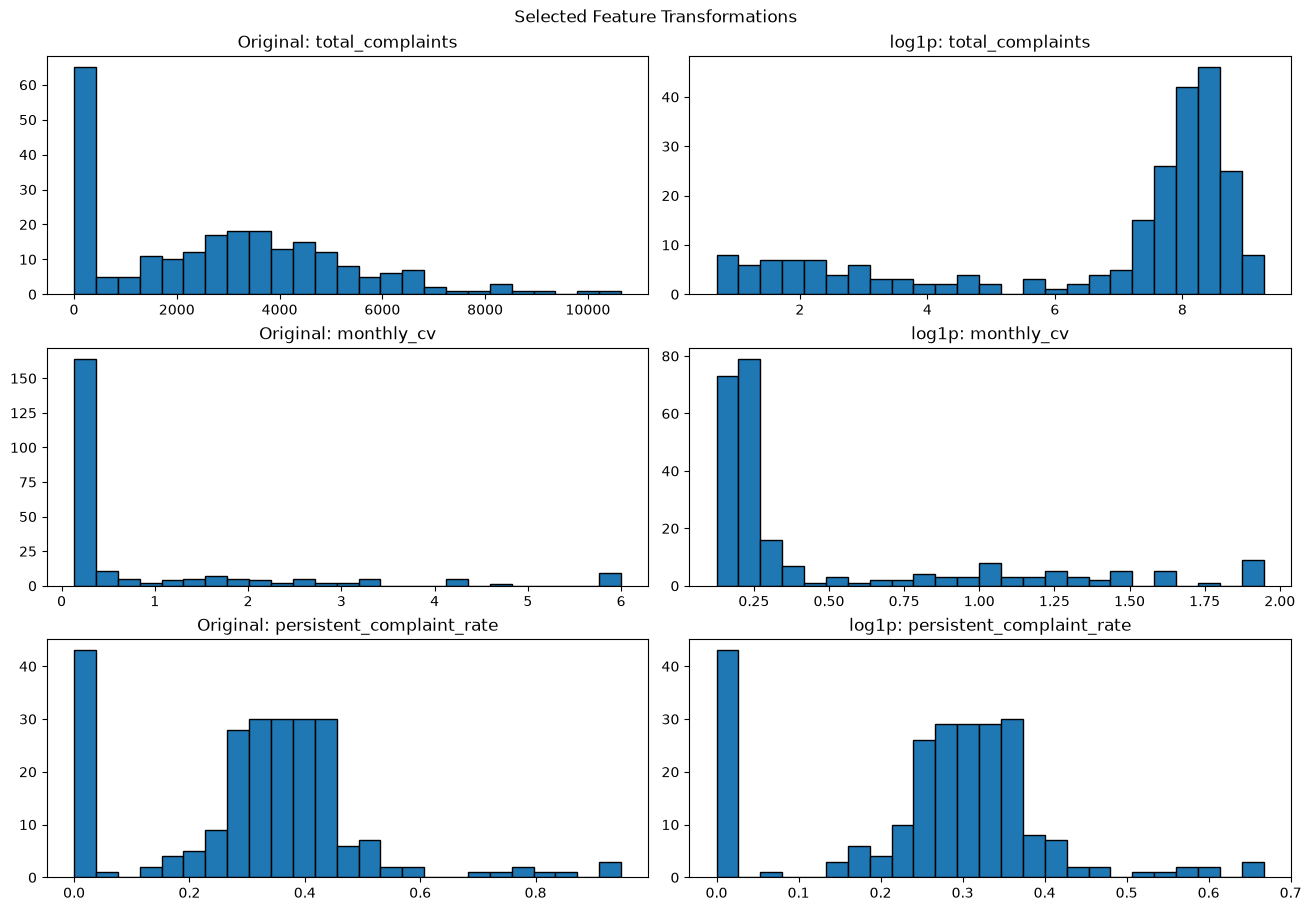

In [13]:
# Inspect log1p effects for the three deliberately transformed features.
# This section is diagnostic; the actual modeling transformation follows below.
log_features = [
    "total_complaints", "monthly_cv", "persistent_complaint_rate"
]
missing = [c for c in log_features if c not in df.columns]
if missing:
    raise ValueError(f"Required log transformation features missing: {missing}")

fig, axes = plt.subplots(len(log_features), 2, figsize=(13, 9), constrained_layout=True)
for i, col in enumerate(log_features):
    if (df[col] < 0).any():
        raise ValueError(f"Negative values in {col}; cannot apply log1p.")
    axes[i, 0].hist(df[col], bins=25, edgecolor="black")
    axes[i, 0].set_title(f"Original: {col}")
    axes[i, 1].hist(np.log1p(df[col]), bins=25, edgecolor="black")
    axes[i, 1].set_title(f"log1p: {col}")
fig.suptitle("Selected Feature Transformations")
fig.savefig(FIGURE_DIR / "original_vs_log_transformed.png", dpi=200, bbox_inches="tight")
plt.show()


In [14]:
# Work on a separate copy to preserve the original selected features.
df_model = df.copy()
log_features = ["total_complaints", "monthly_cv", "persistent_complaint_rate"]
missing = [c for c in log_features if c not in df_model.columns]
if missing:
    raise ValueError(f"Missing required transformation columns: {missing}")
for feature in log_features:
    if not np.isfinite(df_model[feature].to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite values in {feature}")
    if (df_model[feature] < 0).any():
        raise ValueError(f"Negative {feature}; investigate upstream data.")
    df_model[f"{feature}_log"] = np.log1p(df_model[feature])

df_model = df_model.drop(columns=log_features)
print("Transformed fields:", [f"{c}_log" for c in log_features])
print("Original shape:", df.shape, "Transformed shape:", df_model.shape)
print("Missing values:", int(df_model.isna().sum().sum()))
display(df_model.head())


Transformed fields: ['total_complaints_log', 'monthly_cv_log', 'persistent_complaint_rate_log']
Original shape: (238, 21) Transformed shape: (238, 21)
Missing values: 0


,area_id,active_months,repeated_complaint_rate,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,share_sewer_maintenance,share_sidewalk_condition,share_street_condition,...,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance,total_complaints_log,monthly_cv_log,persistent_complaint_rate_log
0,BRONX_10451,36,0.739186,775.731803,0.015267,0.006043,0.071565,0.002545,0.073791,0.268766,...,0.017176,0.013677,0.020674,0.284987,0.000000,0.010814,0.001590,8.053569,0.179134,0.406525
1,BRONX_10452,36,0.704538,721.342271,0.017702,0.009334,0.094947,0.000966,0.141294,0.265529,...,0.020921,0.013840,0.016736,0.214677,0.000322,0.019633,0.000966,8.041735,0.224730,0.372861
2,BRONX_10453,36,0.713626,722.286601,0.014847,0.017156,0.095018,0.000330,0.088090,0.235896,...,0.015836,0.013857,0.019136,0.270538,0.000000,0.022765,0.001980,8.016978,0.263919,0.373621
3,BRONX_10454,36,0.729469,746.359956,0.008052,0.014090,0.080918,0.000805,0.107488,0.283011,...,0.015700,0.013688,0.014493,0.248390,0.000000,0.008857,0.003221,7.818028,0.245801,0.367167
4,BRONX_10455,36,0.757436,749.575947,0.018852,0.021366,0.087558,0.001676,0.085463,0.204860,...,0.009636,0.009636,0.019271,0.317553,0.000000,0.012987,0.002933,7.778211,0.168091,0.410063


The three chosen transformations are `log1p(total_complaints)`, `log1p(monthly_cv)`, and `log1p(persistent_complaint_rate)`. No clipping or hidden imputations are performed. Original values are retained in the upstream `selected_modeling_features.csv` for interpretation.

#### Feature Scaling (StandardScaler vs RobustScaler)
Objective: Compare two scaling methods before selecting the feature representation for K-Means and PCA.
- StandardScaler standardizes features using their means and standard deviations.
- RobustScaler uses medians and interquartile ranges, reducing sensitivity to extreme observations.
We will compare both without modifying df_model.

In [15]:
from sklearn.preprocessing import StandardScaler, RobustScaler

feature_columns = [col for col in df_model.columns if col != "area_id"]
X = df_model[feature_columns].copy()

if X.shape != (len(df_model), len(feature_columns)):
    raise ValueError("Feature matrix shape mismatch.")
if X.isna().any().any() or not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Feature matrix has missing or infinite values.")
if not feature_columns:
    raise ValueError("No modeling features found.")

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()
X_standard = pd.DataFrame(standard_scaler.fit_transform(X), columns=feature_columns, index=X.index)
X_robust = pd.DataFrame(robust_scaler.fit_transform(X), columns=feature_columns, index=X.index)

print("SCALING COMPARISON")
print("Areas:", len(df_model))
print("Numeric features:", len(feature_columns))
print("StandardScaler shape:", X_standard.shape)
print("RobustScaler shape:", X_robust.shape)
display(X_standard.head())
display(X_robust.head())


SCALING COMPARISON
Areas: 238
Numeric features: 20
StandardScaler shape: (238, 20)
RobustScaler shape: (238, 20)


,active_months,repeated_complaint_rate,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,share_sewer_maintenance,share_sidewalk_condition,share_street_condition,share_street_light_condition,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance,total_complaints_log,monthly_cv_log,persistent_complaint_rate_log
0,0.5364,0.642180,0.745068,-0.293940,-0.690784,-0.416468,-0.120602,-0.401367,-0.341953,0.526174,-0.176497,-0.150731,0.072801,1.019358,-0.481013,1.095565,1.543280,0.550210,-0.616007,0.999592
1,0.5364,0.471861,0.547255,-0.237329,-0.607300,-0.112560,-0.345785,0.051623,-0.360961,0.301603,-0.104398,-0.146784,-0.033714,0.448315,0.567093,2.504652,0.620418,0.545703,-0.524325,0.769797
2,0.5364,0.516534,0.550689,-0.303719,-0.408839,-0.111634,-0.436436,-0.305415,-0.535010,0.462096,-0.202280,-0.146369,0.031181,0.902003,-0.481013,3.005036,2.118198,0.536274,-0.445526,0.774980
3,0.5364,0.594413,0.638244,-0.461711,-0.486624,-0.294903,-0.368662,-0.175239,-0.258285,0.437632,-0.204896,-0.150471,-0.094401,0.722123,-0.481013,0.782782,3.951410,0.460499,-0.481958,0.730928
4,0.5364,0.731894,0.649940,-0.210587,-0.302034,-0.208603,-0.244503,-0.323043,-0.717295,0.489508,-0.321661,-0.248680,0.034845,1.283851,-0.481013,1.442732,3.525908,0.445333,-0.638210,1.023743


,active_months,repeated_complaint_rate,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,share_sewer_maintenance,share_sidewalk_condition,share_street_condition,share_street_light_condition,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance,total_complaints_log,monthly_cv_log,persistent_complaint_rate_log
0,0.0,0.924699,1.114091,-0.199303,-0.273981,-0.304916,0.227471,-0.564764,-0.305967,0.978767,-0.142817,0.035188,0.796977,0.874239,0.000000,2.006513,1.446445,0.034240,-0.145940,0.951938
1,0.0,0.562813,0.526082,-0.098884,-0.212135,-0.047830,-0.154806,0.699793,-0.331085,0.648489,0.114138,0.049791,0.422778,0.380211,1.458442,3.902607,0.726559,0.030624,-0.011808,0.679706
2,0.0,0.657732,0.536291,-0.216650,-0.065114,-0.047047,-0.308697,-0.296906,-0.561070,0.884527,-0.234706,0.051324,0.650762,0.772712,0.000000,4.575933,1.894914,0.023060,0.103477,0.685847
3,0.0,0.823205,0.796550,-0.496902,-0.122738,-0.202080,-0.193641,0.066490,-0.195410,0.848548,-0.244029,0.036152,0.209576,0.617092,0.000000,1.585626,3.324926,-0.037732,0.050176,0.633659
4,0.0,1.115319,0.831318,-0.051447,0.014007,-0.129076,0.017133,-0.346115,-0.801938,0.924842,-0.660171,-0.327170,0.663633,1.103060,0.000000,2.473668,2.993010,-0.049898,-0.178423,0.980550


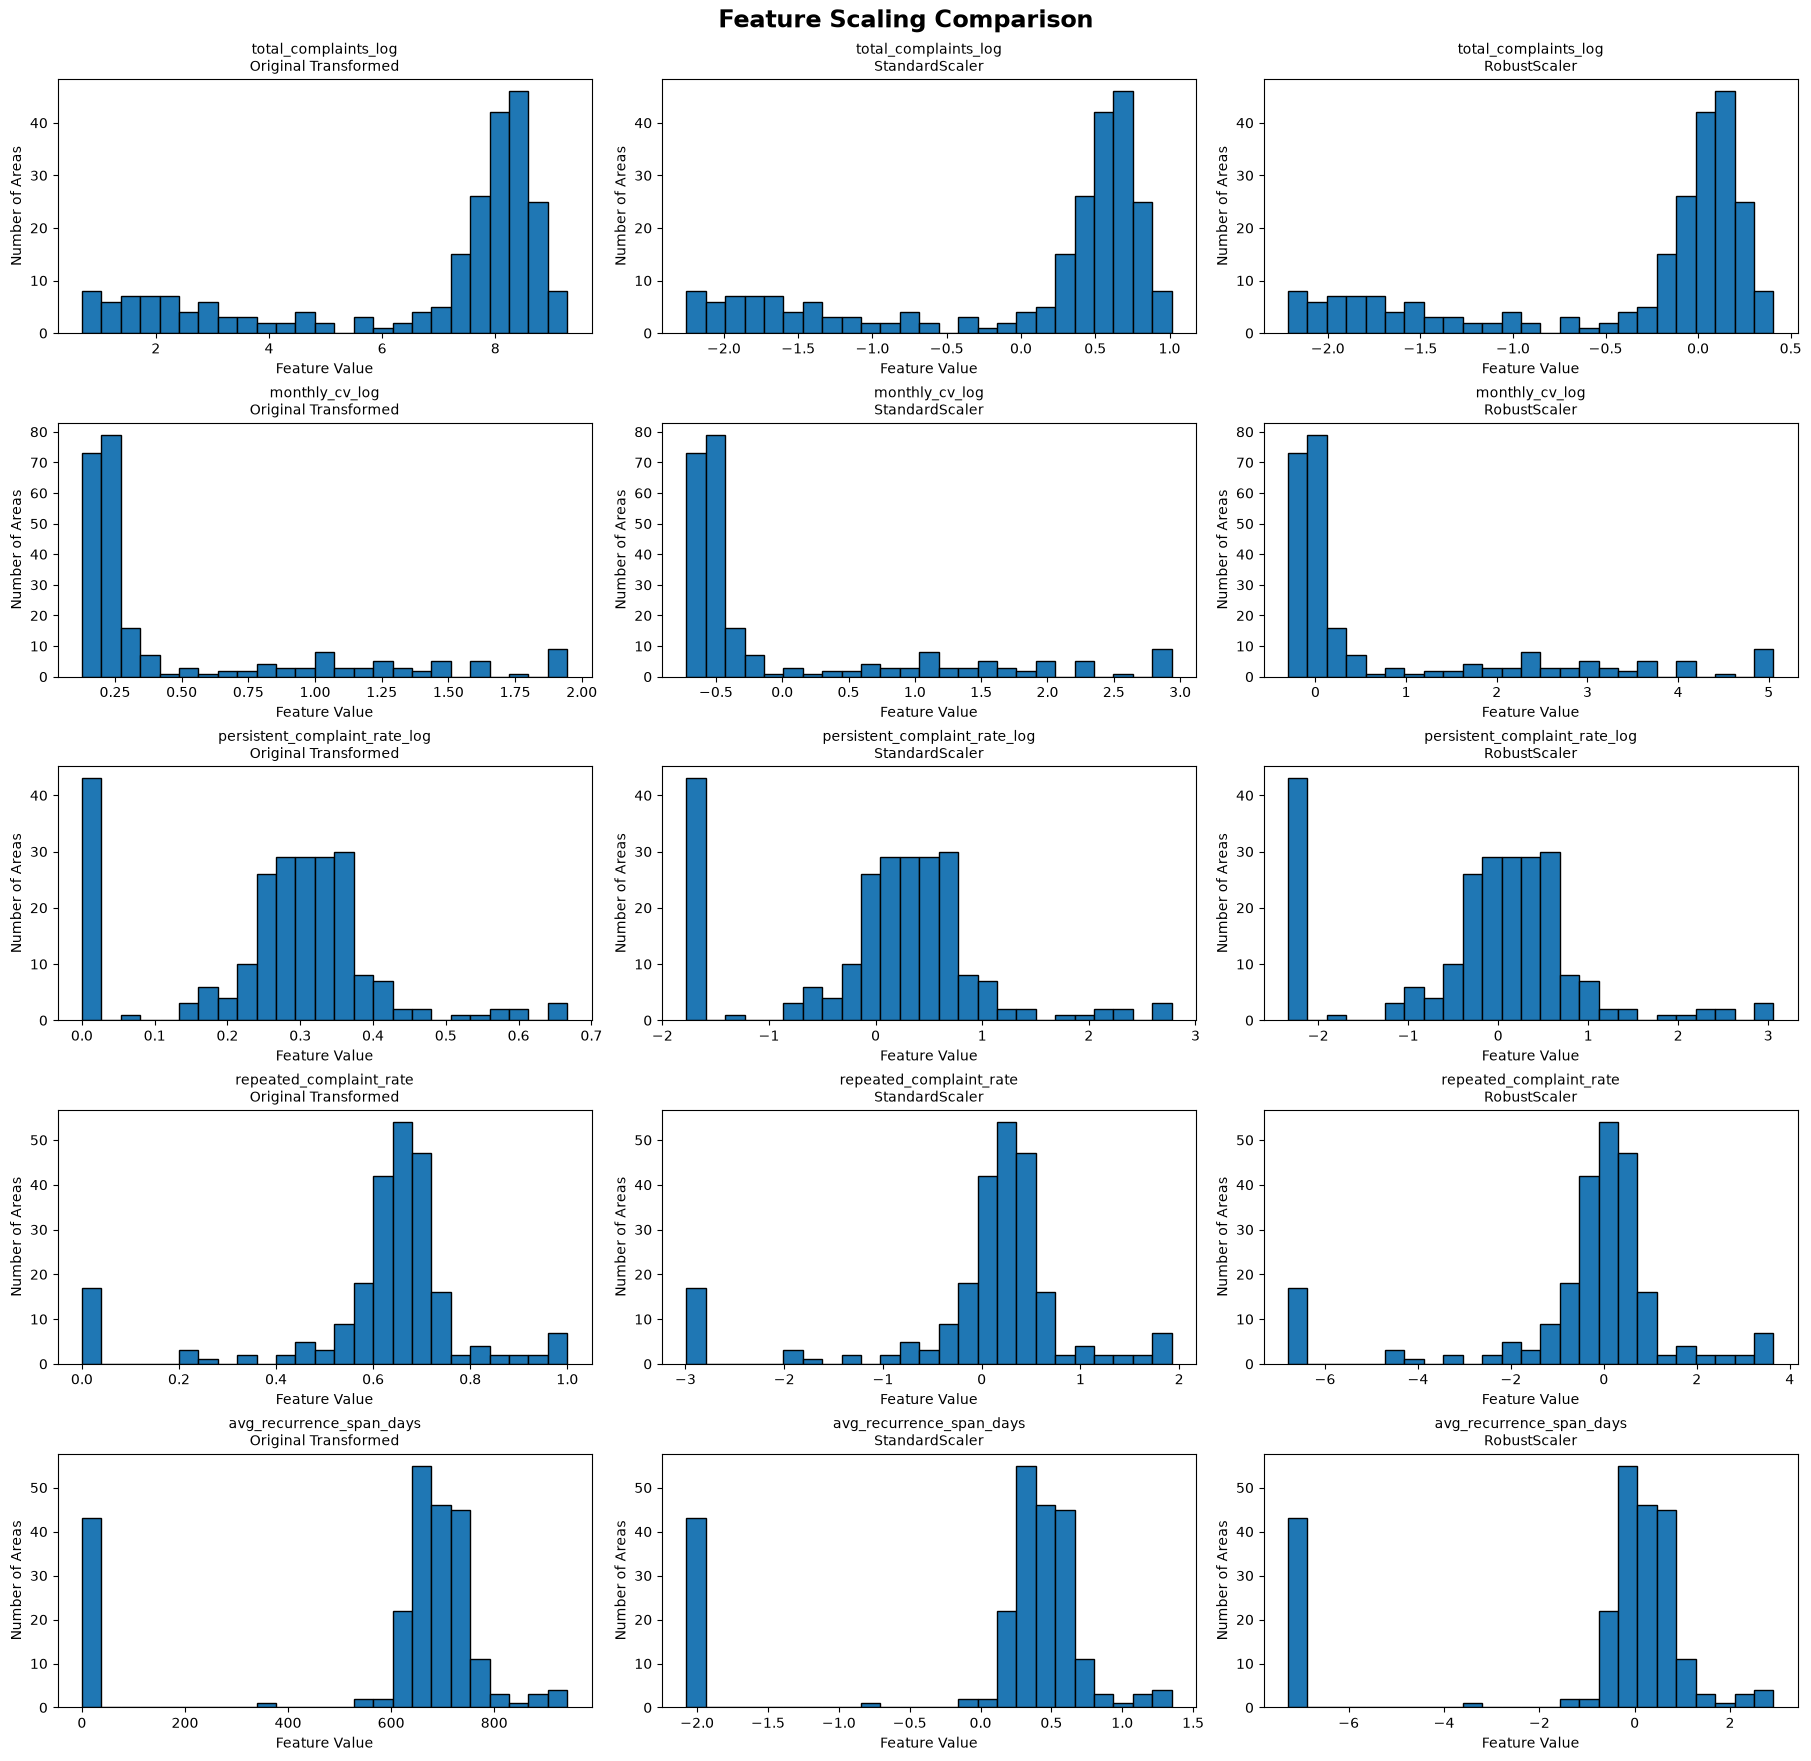

In [16]:
import matplotlib.pyplot as plt
from pathlib import Path

comparison_features = [
    "total_complaints_log",
    "monthly_cv_log",
    "persistent_complaint_rate_log",
    "repeated_complaint_rate",
    "avg_recurrence_span_days"
]

fig, axes = plt.subplots(
    len(comparison_features),
    3,
    figsize=(18, 3.5 * len(comparison_features)),
    constrained_layout=True
)

for i, feature in enumerate(comparison_features):

    for j, (data, label) in enumerate([
        (X, "Original Transformed"),
        (X_standard, "StandardScaler"),
        (X_robust, "RobustScaler")
    ]):

        axes[i, j].hist(
            data[feature],
            bins=25,
            edgecolor="black"
        )

        axes[i, j].set_title(
            f"{feature}\n{label}",
            fontsize=10
        )

        axes[i, j].set_xlabel("Feature Value")
        axes[i, j].set_ylabel("Number of Areas")

fig.suptitle(
    "Feature Scaling Comparison",
    fontsize=17,
    fontweight="bold"
)

output_dir = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "preprocessing"
)

output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "scaling_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
scaling_comparison = pd.DataFrame({
    "feature": feature_columns,
    "original_mean": X.mean().values,
    "original_std": X.std().values,
    "standard_mean": X_standard.mean().values,
    "standard_std": X_standard.std().values,
    "robust_median": X_robust.median().values,
    "robust_iqr": (
        X_robust.quantile(0.75)
        - X_robust.quantile(0.25)
    ).values
})

display(scaling_comparison.round(4))

,feature,original_mean,original_std,standard_mean,standard_std,robust_median,robust_iqr
0,active_months,29.4034,12.3239,0.0,1.0021,0.0,1.0
1,repeated_complaint_rate,0.6085,0.2039,0.0,1.0021,0.0,1.0
2,avg_recurrence_span_days,570.8725,275.5331,0.0,1.0021,0.0,1.0
3,share_curb_condition,0.0279,0.0431,0.0,1.0021,0.0,1.0
4,share_root_sewer_sidewalk_condition,0.0333,0.0395,-0.0,1.0021,0.0,1.0
5,share_sewer,0.1036,0.0771,0.0,1.0021,0.0,1.0
6,share_sewer_maintenance,0.0034,0.0070,0.0,1.0021,0.0,1.0
7,share_sidewalk_condition,0.1336,0.1493,0.0,1.0021,0.0,1.0
8,share_street_condition,0.3270,0.1706,0.0,1.0021,-0.0,1.0
9,share_street_light_condition,0.1429,0.1337,0.0,1.0021,-0.0,1.0


### Important considerations before clustering

Scaling changes feature scales, not skewness or underlying data quality. Category shares are compositional (they sum to one), and rare categories may be disproportionately weighted by ordinary per-feature standardization. In the next section, the baseline uses a square-root (Hellinger-style) transformation for category shares and scales non-compositional features in explicit groups. We later test equal **empirical group variance**, which is a weighting experiment—not a claim that every group has equal practical importance.


- `StandardScaler` centers each nonconstant feature near zero and gives it approximately unit **population** variance.
- `RobustScaler` centers by median and scales by IQR; a zero-IQR sparse feature may remain poorly spread.
- The actual area count and selected feature count are displayed above. They must not be fixed at 214/20 for the full-data run.
- The comparison is diagnostic; neither of these direct all-feature scalers is the final baseline selected below.

**Research caveat:** The previous 100K analysis found large volume-related clusters. After model training, compare clustering results with simple count-based grouping and inspect low-support ZIP areas before claiming meaningful infrastructure peer groups.

#### Build the balanced matrix

In [18]:
from sklearn.preprocessing import StandardScaler

# Reuse the existing four-group modeling approach. Share columns are dynamic:
# the ZIP-level dataset currently has 14 categories because Bridge Condition
# lacks usable ZIP codes, but the code does not hardcode this count.
feature_groups = {
    "intensity": ["total_complaints_log"],
    "temporal": ["monthly_cv_log"],
    "persistence": [
        "repeated_complaint_rate", "persistent_complaint_rate_log",
        "avg_recurrence_span_days"
    ],
    "composition": sorted(c for c in df_model if c.startswith("share_"))
}
selected = [c for group in feature_groups.values() for c in group]
if len(set(selected)) != len(selected):
    raise ValueError("Duplicate features across modeling groups.")
missing = [c for c in selected if c not in df_model.columns]
if missing:
    raise ValueError(f"Missing expected group features: {missing}")
if any(len(cols) == 0 for cols in feature_groups.values()):
    raise ValueError("A modeling feature group is empty.")

# active_months is intentionally excluded from the current K-Means/PCA baseline.
# It remains in the selected source features for future sensitivity analysis.
X_final = pd.DataFrame(index=df_model.index)
group_scalers = {}
for group_name in ("intensity", "temporal", "persistence"):
    cols = feature_groups[group_name]
    scaler = StandardScaler()
    values = scaler.fit_transform(df_model[cols]) / np.sqrt(len(cols))
    X_final[cols] = values
    group_scalers[group_name] = scaler

share_cols = feature_groups["composition"]
shares = df_model[share_cols].to_numpy(dtype=float)
if not np.isfinite(shares).all() or (shares < -1e-10).any():
    raise ValueError("Invalid category-share values.")
if not np.allclose(shares.sum(axis=1), 1.0, atol=1e-5, rtol=0):
    raise ValueError("Modeling category shares do not add to 1.")
X_final[share_cols] = np.sqrt(np.clip(shares, 0, None))

if X_final.isna().any().any() or not np.isfinite(X_final.to_numpy()).all():
    raise ValueError("Final baseline matrix contains invalid values.")
print("BASELINE GROUPED FEATURE MATRIX")
print("Areas:", len(X_final), "Features:", X_final.shape[1])
for group, cols in feature_groups.items():
    print(f"{group}: {len(cols)} features")
display(X_final.head())


BASELINE GROUPED FEATURE MATRIX
Areas: 238 Features: 19
intensity: 1 features
temporal: 1 features
persistence: 3 features
composition: 14 features


,total_complaints_log,monthly_cv_log,repeated_complaint_rate,persistent_complaint_rate_log,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,share_sewer_maintenance,share_sidewalk_condition,share_street_condition,share_street_light_condition,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance
0,0.550210,-0.616007,0.370763,0.577115,0.430165,0.123560,0.077738,0.267516,0.050443,0.271646,0.518426,0.461632,0.131056,0.116948,0.143786,0.533842,0.00000,0.103992,0.039879
1,0.545703,-0.524325,0.272429,0.444442,0.315958,0.133049,0.096611,0.308135,0.031073,0.375891,0.515295,0.427943,0.144639,0.117642,0.129369,0.463332,0.01794,0.140118,0.031073
2,0.536274,-0.445526,0.298221,0.447435,0.317941,0.121847,0.130981,0.308250,0.018164,0.296799,0.485691,0.452275,0.125843,0.117715,0.138331,0.520132,0.00000,0.150880,0.044492
3,0.460499,-0.481958,0.343185,0.422001,0.368490,0.089730,0.118702,0.284461,0.028375,0.327854,0.531988,0.448652,0.125302,0.116994,0.120386,0.498387,0.00000,0.094110,0.056750
4,0.445333,-0.638210,0.422559,0.591058,0.375243,0.137303,0.146170,0.295901,0.040936,0.292340,0.452614,0.456302,0.098161,0.098161,0.138820,0.563519,0.00000,0.113961,0.054153


In [19]:
group_report = []

for group, cols in feature_groups.items():

    values = X_final[cols].to_numpy()

    # Total across-feature variance of each group
    total_variance = np.var(
        values,
        axis=0,
        ddof=0
    ).sum()

    group_report.append({
        "group": group,
        "features": len(cols),
        "total_variance": total_variance
    })

group_report = pd.DataFrame(group_report)

group_report["variance_share_pct"] = (
    100 * group_report["total_variance"]
    / group_report["total_variance"].sum()
)

display(group_report.round(4))

,group,features,total_variance,variance_share_pct
0,intensity,1,1.000,31.2987
1,temporal,1,1.000,31.2987
2,persistence,3,1.000,31.2987
3,composition,14,0.195,6.1039


The table above reports the **actual** variance contribution of each group in the baseline matrix. The categories may contribute less variance than intensity, temporal, or persistence indicators. The balanced experiment below equalizes these empirical totals for comparison; it is not automatically the best choice for interpretation.

In [20]:
# Save baseline for PCA/K-Means, plus reusable preprocessing artifacts.
processed_dir = PROCESSED_DATA_DIR
report_dir = PREPROCESSING_OUTPUT_DIR
processed_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

saved_matrix = X_final.copy()
saved_matrix.insert(0, "area_id", df_model["area_id"].values)
saved_matrix.to_csv(processed_dir / "kmeans_pca_input.csv", index=False)
group_report.to_csv(report_dir / "feature_group_variance.csv", index=False)

joblib.dump(
    {
        "feature_groups": feature_groups,
        "scalers": group_scalers,
        "log_features": log_features,
        "feature_order": X_final.columns.tolist(),
        "selected_source_feature_order": [c for c in df.columns if c != "area_id"],
        "composition_transform": "sqrt",
        "active_months_included": False,
    },
    report_dir / "preprocessing_artifacts.joblib",
)
print("Baseline matrix saved:", processed_dir / "kmeans_pca_input.csv")
print("Shape:", saved_matrix.shape)


Baseline matrix saved: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\kmeans_pca_input.csv
Shape: (238, 20)


### Why compare baseline and equal-group-variance models?

 Compare the final PCA and K-Means results for both matrices (including cluster stability, size, and interpretability), and inspect whether clustering mainly separates high- and low-reporting ZIP areas.

#### Correct Feature-Group Balance

In [21]:
# Preserve baseline, then center and reweight each group so its
# combined empirical variance is 1.0 (experimental balanced matrix).
X_baseline = X_final.copy()
X_balanced = X_baseline.copy()
balance_factors = {}
baseline_group_means = {}
target_variance = 1.0

for group_name, columns in feature_groups.items():
    values = X_baseline[columns]
    group_variance = values.var(ddof=0).sum()
    if not np.isfinite(group_variance) or group_variance <= 1e-12:
        raise ValueError(
            f"Feature group '{group_name}' has zero/negligible variance. "
            "Review selected features and geographic coverage."
        )
    factor = np.sqrt(target_variance / group_variance)
    mean = values.mean()
    X_balanced[columns] = (values - mean) * factor
    balance_factors[group_name] = float(factor)
    baseline_group_means[group_name] = mean.to_dict()

if X_balanced.shape != X_baseline.shape:
    raise ValueError("Balanced and baseline shapes differ.")
if X_balanced.isna().any().any() or not np.isfinite(X_balanced.to_numpy()).all():
    raise ValueError("Balanced matrix contains invalid values.")

print("BALANCED MODELING MATRIX")
print("Areas:", len(X_balanced), "Features:", X_balanced.shape[1])
print("Group factors:", balance_factors)
display(X_balanced.head())


BALANCED MODELING MATRIX
Areas: 238 Features: 19
Group factors: {'intensity': 0.9999999999999999, 'temporal': 1.0, 'persistence': 1.0, 'composition': 2.2644354587122018}


,total_complaints_log,monthly_cv_log,repeated_complaint_rate,persistent_complaint_rate_log,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,share_sewer_maintenance,share_sidewalk_condition,share_street_condition,share_street_light_condition,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance
0,0.550210,-0.616007,0.370763,0.577115,0.430165,-0.032078,-0.147550,-0.041075,0.017309,-0.123371,-0.063633,0.287041,-0.000696,0.009889,0.079908,0.421281,-0.014779,0.134729,0.052351
1,0.545703,-0.524325,0.272429,0.444442,0.315958,-0.010592,-0.104813,0.050902,-0.026552,0.112686,-0.070722,0.210753,0.030063,0.011461,0.047263,0.261616,0.025845,0.216536,0.032411
2,0.536274,-0.445526,0.298221,0.447435,0.317941,-0.035959,-0.026985,0.051164,-0.055786,-0.066412,-0.137760,0.265853,-0.012500,0.011626,0.067557,0.390237,-0.014779,0.240905,0.062797
3,0.460499,-0.481958,0.343185,0.422001,0.368490,-0.108684,-0.054790,-0.002706,-0.032662,0.003909,-0.032923,0.257647,-0.013725,0.009993,0.026921,0.340996,-0.014779,0.112353,0.090555
4,0.445333,-0.638210,0.422559,0.591058,0.375243,-0.000959,0.007410,0.023201,-0.004220,-0.076508,-0.212660,0.274970,-0.075184,-0.032653,0.068664,0.488483,-0.014779,0.157304,0.084673


In [22]:
balance_report = []

for group_name, columns in feature_groups.items():

    variance = (
        X_balanced[columns]
        .var(ddof=0)
        .sum()
    )

    balance_report.append({
        "group": group_name,
        "features": len(columns),
        "total_variance": variance
    })

balance_report = pd.DataFrame(balance_report)

balance_report["variance_share_pct"] = (
    balance_report["total_variance"]
    / balance_report["total_variance"].sum()
    * 100
)

display(balance_report.round(4))

,group,features,total_variance,variance_share_pct
0,intensity,1,1.0,25.0
1,temporal,1,1.0,25.0
2,persistence,3,1.0,25.0
3,composition,14,1.0,25.0


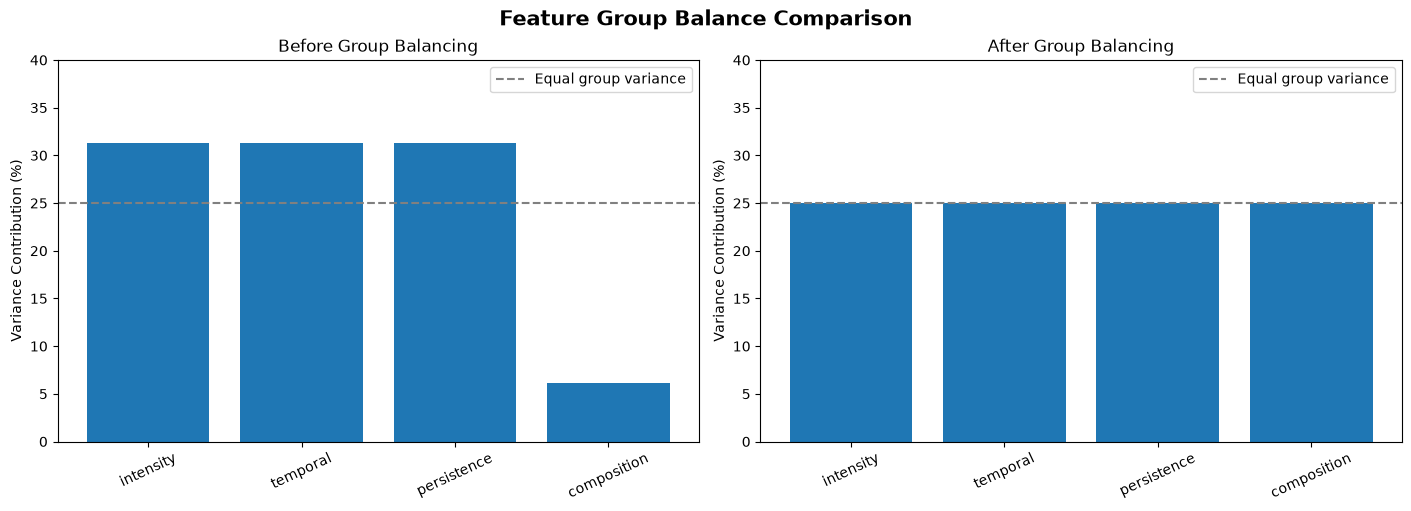

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

axes[0].bar(
    group_report["group"],
    group_report["variance_share_pct"]
)

axes[0].set_title("Before Group Balancing")
axes[0].set_ylabel("Variance Contribution (%)")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(
    balance_report["group"],
    balance_report["variance_share_pct"]
)

axes[1].set_title("After Group Balancing")
axes[1].set_ylabel("Variance Contribution (%)")
axes[1].tick_params(axis="x", rotation=25)

for ax in axes:
    ax.set_ylim(0, 40)
    ax.axhline(
        y=25,
        color="gray",
        linestyle="--",
        label="Equal group variance"
    )
    ax.legend()

fig.suptitle(
    "Feature Group Balance Comparison",
    fontsize=15,
    fontweight="bold"
)

figure_dir = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "preprocessing"
)

figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "group_balance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
output_dir = PROCESSED_DATA_DIR
output_dir.mkdir(parents=True, exist_ok=True)

balanced_output = X_balanced.copy()
balanced_output.insert(0, "area_id", df_model["area_id"].values)
balanced_output.to_csv(output_dir / "kmeans_pca_input_balanced.csv", index=False)

balance_report.to_csv(
    PREPROCESSING_OUTPUT_DIR / "balanced_feature_group_variance.csv", index=False
)
joblib.dump(
    {
        "feature_groups": feature_groups,
        "group_scalers": group_scalers,
        "log_features": log_features,
        "balance_factors": balance_factors,
        "baseline_group_means": baseline_group_means,
        "feature_order": X_balanced.columns.tolist(),
        "selected_source_feature_order": [c for c in df.columns if c != "area_id"],
        "composition_transform": "sqrt",
        "excluded_feature": "active_months"
    },
    PREPROCESSING_OUTPUT_DIR / "balanced_preprocessing_artifacts.joblib"
)
print("Balanced matrix saved:", output_dir / "kmeans_pca_input_balanced.csv")
print("Shape:", balanced_output.shape)


Balanced matrix saved: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\kmeans_pca_input_balanced.csv
Shape: (238, 20)


Our next phase will use these matrices for PCA and K-Means experiments, comparing clustering quality, stability and interpretability rather than assuming that equal variance automatically produces the best clusters.

## 8. Final Preprocessing Integrity Verification

Validate the saved clustering matrices before proceeding to PCA and K-Means.

The objective is to confirm data integrity, feature consistency,
geographic-area alignment and successful output persistence.

In [25]:
baseline_path = PROCESSED_DATA_DIR / "kmeans_pca_input.csv"
balanced_path = PROCESSED_DATA_DIR / "kmeans_pca_input_balanced.csv"
for path in (baseline_path, balanced_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved input matrix: {path}")

baseline_df = pd.read_csv(baseline_path)
balanced_df = pd.read_csv(balanced_path)
expected_ids = df_model["area_id"].astype(str).tolist()
expected_columns = ["area_id", *X_balanced.columns.tolist()]
expected_shape = (len(df_model), len(expected_columns))

for name, dataset in (("Baseline", baseline_df), ("Balanced", balanced_df)):
    if dataset.shape != expected_shape:
        raise ValueError(f"{name} matrix shape {dataset.shape}, expected {expected_shape}")
    if dataset.columns.tolist() != expected_columns:
        raise ValueError(f"{name}: feature names/order differ")
    if dataset["area_id"].astype(str).tolist() != expected_ids:
        raise ValueError(f"{name}: area ID alignment mismatch")
    if not dataset["area_id"].is_unique:
        raise ValueError(f"{name}: duplicate area IDs")
    numeric = dataset.drop(columns="area_id")
    if numeric.isna().any().any() or not np.isfinite(numeric.to_numpy()).all():
        raise ValueError(f"{name}: missing/nonfinite feature values")
    print(f"{name}: PASSED — {len(dataset)} areas, {numeric.shape[1]} numerical features")

np.testing.assert_allclose(
    baseline_df.drop(columns="area_id").to_numpy(),
    X_baseline.to_numpy(), rtol=1e-10, atol=1e-10
)
np.testing.assert_allclose(
    balanced_df.drop(columns="area_id").to_numpy(),
    X_balanced.to_numpy(), rtol=1e-10, atol=1e-10
)
print("ALL PREPROCESSING INTEGRITY CHECKS PASSED")


Baseline: PASSED — 238 areas, 19 numerical features
Balanced: PASSED — 238 areas, 19 numerical features
ALL PREPROCESSING INTEGRITY CHECKS PASSED


Next, run **PCA** and **K-Means** on both `kmeans_pca_input.csv` (baseline) and `kmeans_pca_input_balanced.csv` (equal-variance experiment). Compare explained variance, cluster sizes, silhouette scores, and meaningful infrastructure category patterns. The ZIP areas may differ from the original 100K analysis.

### Interpretation and methodological caution

- The 4 modeling groups—**complaint intensity**, **temporal variability**, **persistence**, and **complaint-category composition**—are deliberately constructed feature sets.
- Group balancing produces approximately **25% of empirical variance per group** when all four groups are nonconstant; it is an experimental weighting, not an estimated real-world importance.
- `active_months` remains in the selected input CSV but is intentionally excluded from the baseline matrix to reduce temporal redundancy. Revisit this during sensitivity analysis.
- ZIP areas with few recorded complaints can have unstable category proportions and recurrence rates. Assess sample support and compare against simpler count-based and composition-only baselines.
- All results are **patterns of reported complaints** and cannot directly establish actual physical infrastructure condition.

**Saved files:**

- `data/processed/kmeans_pca_input.csv`
- `data/processed/kmeans_pca_input_balanced.csv`
- `outputs/tables/preprocessing/feature_group_variance.csv`
- `outputs/tables/preprocessing/balanced_feature_group_variance.csv`
- `outputs/tables/preprocessing/preprocessing_artifacts.joblib`
- `outputs/tables/preprocessing/balanced_preprocessing_artifacts.joblib`


### Locate the Original Scaling and Feature-Weighting Code

In [1]:
from pathlib import Path
import json

print("PREPROCESSING TRANSFORMATION CODE INSPECTION")
print("=" * 65)

project_root = Path(
    r"D:\Urban-Infrastructure-Pulse-Intelligence"
)

notebooks_to_inspect = [
    project_root / "notebooks" / "02_data_preprocessing.ipynb",
    project_root / "notebooks" / "03_pca_analysis.ipynb",
    project_root / "notebooks" / "04_kmeans_clustering.ipynb",
]

keywords = [
    "StandardScaler",
    "RobustScaler",
    "MinMaxScaler",
    "fit_transform",
    "np.log1p",
    "sqrt",
    "weight",
    "kmeans_pca_input.csv",
    "X_baseline",
]

for notebook_path in notebooks_to_inspect:

    print(f"\nNOTEBOOK: {notebook_path.name}")
    print("-" * 65)

    if not notebook_path.exists():
        print("Not found")
        continue

    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for index, cell in enumerate(notebook["cells"], start=1):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        matched = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if not matched:
            continue

        print(f"\nCell {index}")
        print("Matched keywords:", ", ".join(matched))

        relevant_lines = [
            line.strip()
            for line in source.splitlines()
            if any(
                keyword.lower() in line.lower()
                for keyword in keywords
            )
        ]

        for line in relevant_lines[:12]:
            print(" ", line[:180])

print("\nINSPECTION COMPLETED")

PREPROCESSING TRANSFORMATION CODE INSPECTION

NOTEBOOK: 02_data_preprocessing.ipynb
-----------------------------------------------------------------

Cell 10
Matched keywords: weight
  fontweight="bold"

Cell 15
Matched keywords: weight
  axes[i].set_title(feature, fontsize=10, fontweight="bold")
  fontweight="bold"

Cell 17
Matched keywords: weight
  axes[0].set_title("Feature Correlation Matrix", fontweight="bold")
  fontweight="bold"

Cell 22
Matched keywords: np.log1p
  axes[i, 1].hist(np.log1p(df[col]), bins=25, edgecolor="black")

Cell 23
Matched keywords: np.log1p
  df_model[f"{feature}_log"] = np.log1p(df_model[feature])

Cell 26
Matched keywords: StandardScaler, RobustScaler, fit_transform
  from sklearn.preprocessing import StandardScaler, RobustScaler
  standard_scaler = StandardScaler()
  robust_scaler = RobustScaler()
  X_standard = pd.DataFrame(standard_scaler.fit_transform(X), columns=feature_columns, index=X.index)
  X_robust = pd.DataFrame(robust_scaler.fit_transform(

In [2]:
from pathlib import Path
import json
import re

print("EXACT FEATURE TRANSFORMATION CODE SEARCH")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

files = [
    root / "notebooks" / "02_data_preprocessing.ipynb",
    root / "notebooks" / "03_pca_analysis.ipynb",
    root / "notebooks" / "04_kmeans_clustering.ipynb",
]

patterns = [
    r"\bStandardScaler\b",
    r"\bRobustScaler\b",
    r"\bMinMaxScaler\b",
    r"\bfit_transform\s*\(",
    r"\btransform\s*\(",
    r"\bnp\.log1p\s*\(",
    r"\bnp\.sqrt\s*\(",
    r"kmeans_pca_input",
    r"feature_weights",
    r"group_weights",
    r"weighted_features",
    r"X_baseline\s*=",
]

for path in files:

    print(f"\nNOTEBOOK: {path.name}")
    print("-" * 65)

    if not path.exists():
        print("Not found")
        continue

    notebook = json.loads(
        path.read_text(encoding="utf-8")
    )

    matches = []

    for cell_number, cell in enumerate(
        notebook["cells"], start=1
    ):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        # Exclude comments and obvious plotting statements
        relevant_lines = [
            line for line in source.splitlines()
            if not line.lstrip().startswith("#")
            and "fontweight" not in line.lower()
        ]

        relevant_source = "\n".join(relevant_lines)

        found = [
            pattern
            for pattern in patterns
            if re.search(pattern, relevant_source)
        ]

        if found:
            matches.append((cell_number, found))

    print("Relevant cells found:", len(matches))

    for cell_number, found in matches:
        print(
            f"Cell {cell_number}: "
            + ", ".join(found)
        )

print("\nSEARCH COMPLETED")

EXACT FEATURE TRANSFORMATION CODE SEARCH

NOTEBOOK: 02_data_preprocessing.ipynb
-----------------------------------------------------------------
Relevant cells found: 10
Cell 22: \bnp\.log1p\s*\(
Cell 23: \bnp\.log1p\s*\(
Cell 26: \bStandardScaler\b, \bRobustScaler\b, \bfit_transform\s*\(
Cell 27: \bStandardScaler\b, \bRobustScaler\b
Cell 32: \bStandardScaler\b, \bfit_transform\s*\(, \bnp\.sqrt\s*\(
Cell 35: kmeans_pca_input
Cell 38: \bnp\.sqrt\s*\(, X_baseline\s*=
Cell 41: kmeans_pca_input
Cell 44: kmeans_pca_input
Cell 48: \bStandardScaler\b, \bRobustScaler\b, \bMinMaxScaler\b, kmeans_pca_input

NOTEBOOK: 03_pca_analysis.ipynb
-----------------------------------------------------------------
Relevant cells found: 2
Cell 5: kmeans_pca_input
Cell 28: \btransform\s*\(

NOTEBOOK: 04_kmeans_clustering.ipynb
-----------------------------------------------------------------
Relevant cells found: 6
Cell 4: kmeans_pca_input, X_baseline\s*=
Cell 6: \btransform\s*\(
Cell 114: \btransform\s*\(,

In [3]:
from pathlib import Path
import json

print("ORIGINAL PREPROCESSING CODE REVIEW")
print("=" * 65)

notebook_path = Path(
    r"D:\Urban-Infrastructure-Pulse-Intelligence"
) / "notebooks" / "02_data_preprocessing.ipynb"

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

target_cells = [26, 27, 32, 35, 38, 41, 44]

for cell_number in target_cells:

    cell = notebook["cells"][cell_number - 1]

    print("\n" + "=" * 65)
    print(f"CELL {cell_number}")
    print("=" * 65)

    print("".join(cell.get("source", [])))

print("\nCODE REVIEW COMPLETED")

ORIGINAL PREPROCESSING CODE REVIEW

CELL 26
from sklearn.preprocessing import StandardScaler, RobustScaler

feature_columns = [col for col in df_model.columns if col != "area_id"]
X = df_model[feature_columns].copy()

if X.shape != (len(df_model), len(feature_columns)):
    raise ValueError("Feature matrix shape mismatch.")
if X.isna().any().any() or not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Feature matrix has missing or infinite values.")
if not feature_columns:
    raise ValueError("No modeling features found.")

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()
X_standard = pd.DataFrame(standard_scaler.fit_transform(X), columns=feature_columns, index=X.index)
X_robust = pd.DataFrame(robust_scaler.fit_transform(X), columns=feature_columns, index=X.index)

print("SCALING COMPARISON")
print("Areas:", len(df_model))
print("Numeric features:", len(feature_columns))
print("StandardScaler shape:", X_standard.shape)
print("RobustScaler shape:", X_

In [4]:
from pathlib import Path
import json

notebook_path = (
    Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
    / "notebooks"
    / "02_data_preprocessing.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cell_number = 38
cell = notebook["cells"][cell_number - 1]

print("CELL 38 — BASELINE FEATURE CONSTRUCTION")
print("=" * 60)

source = "".join(cell.get("source", []))

for line_number, line in enumerate(source.splitlines(), start=1):
    print(f"{line_number:03d}: {line}")

CELL 38 — BASELINE FEATURE CONSTRUCTION
001: # Preserve baseline, then center and reweight each group so its
002: # combined empirical variance is 1.0 (experimental balanced matrix).
003: X_baseline = X_final.copy()
004: X_balanced = X_baseline.copy()
005: balance_factors = {}
006: baseline_group_means = {}
007: target_variance = 1.0
008: 
009: for group_name, columns in feature_groups.items():
010:     values = X_baseline[columns]
011:     group_variance = values.var(ddof=0).sum()
012:     if not np.isfinite(group_variance) or group_variance <= 1e-12:
013:         raise ValueError(
014:             f"Feature group '{group_name}' has zero/negligible variance. "
015:             "Review selected features and geographic coverage."
016:         )
017:     factor = np.sqrt(target_variance / group_variance)
018:     mean = values.mean()
019:     X_balanced[columns] = (values - mean) * factor
020:     balance_factors[group_name] = float(factor)
021:     baseline_group_means[group_name] = mea

In [5]:
from pathlib import Path
import json
import re

notebook_path = (
    Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
    / "notebooks"
    / "02_data_preprocessing.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

print("X_FINAL CONSTRUCTION INSPECTION")
print("=" * 60)

patterns = [
    r"\bX_final\s*=",
    r"\bX_final\s*\[",
    r"\bfeature_groups\s*=",
    r"\bStandardScaler\s*\(",
    r"\bRobustScaler\s*\(",
    r"\bfit_transform\s*\(",
]

for cell_number, cell in enumerate(
    notebook["cells"], start=1
):
    if cell.get("cell_type") != "code":
        continue

    lines = "".join(cell.get("source", [])).splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if not line.lstrip().startswith("#")
        and any(re.search(p, line) for p in patterns)
    ]

    if not matches:
        continue

    print(f"\nCELL {cell_number}")

    selected = set()
    for i in matches:
        selected.update(
            range(max(0, i - 3), min(len(lines), i + 6))
        )

    for i in sorted(selected):
        print(f"{i + 1:03d}: {lines[i]}")

print("\nINSPECTION COMPLETED")

X_FINAL CONSTRUCTION INSPECTION

CELL 26
010: if not feature_columns:
011:     raise ValueError("No modeling features found.")
012: 
013: standard_scaler = StandardScaler()
014: robust_scaler = RobustScaler()
015: X_standard = pd.DataFrame(standard_scaler.fit_transform(X), columns=feature_columns, index=X.index)
016: X_robust = pd.DataFrame(robust_scaler.fit_transform(X), columns=feature_columns, index=X.index)
017: 
018: print("SCALING COMPARISON")
019: print("Areas:", len(df_model))
020: print("Numeric features:", len(feature_columns))
021: print("StandardScaler shape:", X_standard.shape)

CELL 32
003: # Reuse the existing four-group modeling approach. Share columns are dynamic:
004: # the ZIP-level dataset currently has 14 categories because Bridge Condition
005: # lacks usable ZIP codes, but the code does not hardcode this count.
006: feature_groups = {
007:     "intensity": ["total_complaints_log"],
008:     "temporal": ["monthly_cv_log"],
009:     "persistence": [
010:         "r

In [6]:
from pathlib import Path
import json

notebook_path = (
    Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
    / "notebooks"
    / "02_data_preprocessing.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

cell_number = 32
source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

lines = source.splitlines()

print("CELL 32 — FINAL FEATURE SCALING LOGIC")
print("=" * 60)
print("Total lines:", len(lines))

# Print in smaller sections to avoid truncated output
for start in range(0, len(lines), 20):
    end = min(start + 20, len(lines))

    print(f"\n--- Lines {start + 1} to {end} ---")

    for i in range(start, end):
        print(f"{i + 1:03d}: {lines[i]}")

CELL 32 — FINAL FEATURE SCALING LOGIC
Total lines: 49

--- Lines 1 to 20 ---
001: from sklearn.preprocessing import StandardScaler
002: 
003: # Reuse the existing four-group modeling approach. Share columns are dynamic:
004: # the ZIP-level dataset currently has 14 categories because Bridge Condition
005: # lacks usable ZIP codes, but the code does not hardcode this count.
006: feature_groups = {
007:     "intensity": ["total_complaints_log"],
008:     "temporal": ["monthly_cv_log"],
009:     "persistence": [
010:         "repeated_complaint_rate", "persistent_complaint_rate_log",
011:         "avg_recurrence_span_days"
012:     ],
013:     "composition": sorted(c for c in df_model if c.startswith("share_"))
014: }
015: selected = [c for group in feature_groups.values() for c in group]
016: if len(set(selected)) != len(selected):
017:     raise ValueError("Duplicate features across modeling groups.")
018: missing = [c for c in selected if c not in df_model.columns]
019: if missing:
020

In [7]:
from pathlib import Path
import json

notebook_path = (
    Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
    / "notebooks"
    / "02_data_preprocessing.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][31].get("source", [])
)

lines = source.splitlines()

print("CELL 32 — SCALING IMPLEMENTATION")
print("=" * 60)

for i in range(20, min(45, len(lines))):
    print(f"{i + 1:03d}: {lines[i]}")

CELL 32 — SCALING IMPLEMENTATION
021: if any(len(cols) == 0 for cols in feature_groups.values()):
022:     raise ValueError("A modeling feature group is empty.")
023: 
024: # active_months is intentionally excluded from the current K-Means/PCA baseline.
025: # It remains in the selected source features for future sensitivity analysis.
026: X_final = pd.DataFrame(index=df_model.index)
027: group_scalers = {}
028: for group_name in ("intensity", "temporal", "persistence"):
029:     cols = feature_groups[group_name]
030:     scaler = StandardScaler()
031:     values = scaler.fit_transform(df_model[cols]) / np.sqrt(len(cols))
032:     X_final[cols] = values
033:     group_scalers[group_name] = scaler
034: 
035: share_cols = feature_groups["composition"]
036: shares = df_model[share_cols].to_numpy(dtype=float)
037: if not np.isfinite(shares).all() or (shares < -1e-10).any():
038:     raise ValueError("Invalid category-share values.")
039: if not np.allclose(shares.sum(axis=1), 1.0, atol=1e-

In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler

print("FITTED GROUP SCALER VERIFICATION")
print("=" * 60)

required_groups = (
    "intensity",
    "temporal",
    "persistence"
)

assert "group_scalers" in globals(), (
    "group_scalers is unavailable. "
    "Do not refit scalers until the original "
    "training inputs have been verified."
)

assert "feature_groups" in globals()
assert "df_model" in globals()
assert "X_final" in globals()

for group_name in required_groups:

    print(f"\nGroup: {group_name}")

    scaler = group_scalers[group_name]
    columns = feature_groups[group_name]

    assert isinstance(scaler, StandardScaler)
    assert hasattr(scaler, "mean_")
    assert hasattr(scaler, "scale_")

    # Apply existing fitted scaler only.
    reproduced = (
        scaler.transform(df_model[columns])
        / np.sqrt(len(columns))
    )

    expected = X_final[columns].to_numpy(
        dtype=float
    )

    matches = np.allclose(
        reproduced,
        expected,
        rtol=1e-10,
        atol=1e-12
    )

    maximum_difference = np.max(
        np.abs(reproduced - expected)
    )

    print("Features:", columns)
    print("Fitted observations:", scaler.n_samples_seen_)
    print("Transformation matches:", matches)
    print("Maximum difference:", maximum_difference)

    assert matches, (
        f"{group_name}: Scaler reproduction failed."
    )

# Verify the composition transformation.
share_columns = feature_groups["composition"]

shares = df_model[share_columns].to_numpy(
    dtype=float
)

reproduced_composition = np.sqrt(
    np.clip(shares, 0, None)
)

expected_composition = X_final[
    share_columns
].to_numpy(dtype=float)

composition_matches = np.allclose(
    reproduced_composition,
    expected_composition,
    rtol=1e-10,
    atol=1e-12
)

print("\nComposition transformation matches:",
      composition_matches)

assert composition_matches, (
    "Composition transformation reproduction failed."
)

print("\nALL GROUP TRANSFORMATIONS VERIFIED")

FITTED GROUP SCALER VERIFICATION


AssertionError: group_scalers is unavailable. Do not refit scalers until the original training inputs have been verified.

In [9]:
print("PREPROCESSING KERNEL STATE INSPECTION")
print("=" * 60)

required_variables = [
    "df_model",
    "feature_groups",
    "group_scalers",
    "X_final",
    "X_baseline",
    "X_balanced",
    "standard_scaler",
    "robust_scaler",
]

for name in required_variables:

    if name in globals():

        obj = globals()[name]

        print(
            f"{name}: AVAILABLE "
            f"| Type: {type(obj).__name__} "
            f"| Shape: {getattr(obj, 'shape', 'N/A')}"
        )

    else:
        print(f"{name}: NOT AVAILABLE")

print("\nINSPECTION COMPLETED")

PREPROCESSING KERNEL STATE INSPECTION
df_model: NOT AVAILABLE
feature_groups: NOT AVAILABLE
group_scalers: NOT AVAILABLE
X_final: NOT AVAILABLE
X_baseline: NOT AVAILABLE
X_balanced: NOT AVAILABLE
standard_scaler: NOT AVAILABLE
robust_scaler: NOT AVAILABLE

INSPECTION COMPLETED


In [10]:
from pathlib import Path
import json
import re

print("ORIGINAL MODELING INPUT LINEAGE")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

notebook_path = (
    root / "notebooks" / "02_data_preprocessing.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

patterns = [
    r"\bdf_model\s*=",
    r"\bdf_model\s*\[",
    r"\bread_csv\s*\(",
    r"\bread_parquet\s*\(",
    r"\bselect_modeling_features\s*\(",
]

for cell_number, cell in enumerate(
    notebook["cells"], start=1
):

    if cell.get("cell_type") != "code":
        continue

    lines = "".join(
        cell.get("source", [])
    ).splitlines()

    matched_indices = [
        i for i, line in enumerate(lines)
        if not line.lstrip().startswith("#")
        and any(re.search(p, line) for p in patterns)
    ]

    if not matched_indices:
        continue

    print(f"\nCELL {cell_number}")

    selected_lines = set()

    for i in matched_indices:
        selected_lines.update(
            range(
                max(0, i - 2),
                min(len(lines), i + 4)
            )
        )

    for i in sorted(selected_lines):
        print(f"{i + 1:03d}: {lines[i]}")

print("\nLINEAGE INSPECTION COMPLETED")

ORIGINAL MODELING INPUT LINEAGE

CELL 3
005:     )
006: 
007: df = pd.read_csv(INPUT_FILE, low_memory=False)
008: if df.empty:
009:     raise ValueError("Selected modeling dataset is empty.")
010: if "area_id" not in df.columns:

CELL 23
001: # Work on a separate copy to preserve the original selected features.
002: df_model = df.copy()
003: log_features = ["total_complaints", "monthly_cv", "persistent_complaint_rate"]
004: missing = [c for c in log_features if c not in df_model.columns]
005: if missing:
006:     raise ValueError(f"Missing required transformation columns: {missing}")
007: for feature in log_features:
008:     if not np.isfinite(df_model[feature].to_numpy(dtype=float)).all():
009:         raise ValueError(f"Non-finite values in {feature}")
010:     if (df_model[feature] < 0).any():
011:         raise ValueError(f"Negative {feature}; investigate upstream data.")
012:     df_model[f"{feature}_log"] = np.log1p(df_model[feature])
013: 
014: df_model = df_model.drop(columns=

In [11]:
from pathlib import Path
import json
import re
import pandas as pd

print("ORIGINAL PREPROCESSING INPUT VERIFICATION")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

notebook_path = (
    root / "notebooks" / "02_data_preprocessing.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

print("\n1. INPUT_FILE definitions and references")

for cell_number, cell in enumerate(
    notebook["cells"], start=1
):
    if cell.get("cell_type") != "code":
        continue

    lines = "".join(cell.get("source", [])).splitlines()

    for line_number, line in enumerate(lines, start=1):
        if re.search(r"\bINPUT_FILE\b", line):
            print(
                f"Cell {cell_number}, line {line_number}: "
                f"{line.strip()}"
            )

print("\n2. Candidate source files")

processed_dir = root / "data" / "processed"

for path in sorted(processed_dir.glob("*.csv")):
    print(
        path.name,
        "| Size:",
        path.stat().st_size,
        "bytes"
    )

print("\n3. Current kernel input path")

if "INPUT_FILE" in globals():
    print("INPUT_FILE:", INPUT_FILE)
    print("Exists:", Path(INPUT_FILE).exists())
else:
    print("INPUT_FILE is not loaded in this kernel.")

print("\nINSPECTION COMPLETED")

ORIGINAL PREPROCESSING INPUT VERIFICATION

1. INPUT_FILE definitions and references
Cell 2, line 27: INPUT_FILE = PROCESSED_DATA_DIR / "selected_modeling_features.csv"
Cell 2, line 36: print("Input:", INPUT_FILE)
Cell 3, line 1: if not INPUT_FILE.is_file():
Cell 3, line 3: f"Selected modeling dataset not found: {INPUT_FILE}\n"
Cell 3, line 7: df = pd.read_csv(INPUT_FILE, low_memory=False)

2. Candidate source files
area_composition_features.csv | Size: 96698 bytes
area_features_by_zip.csv | Size: 41463 bytes
area_modeling_features.csv | Size: 112189 bytes
area_modeling_features_with_persistence.csv | Size: 126989 bytes
kmeans_pca_input.csv | Size: 80135 bytes
kmeans_pca_input_balanced.csv | Size: 95858 bytes
nyc311_all_15_complaints_2023_2025.csv | Size: 412951088 bytes
nyc311_geographic_valid.csv | Size: 101399704 bytes
nyc311_infrastructure_100k_cleaned.csv | Size: 67375275 bytes
nyc311_infrastructure_cleaned.csv | Size: 469576698 bytes
nyc311_infrastructure_geographic.csv | Size: 43

In [12]:
import pandas as pd
import numpy as np
from pathlib import Path

print("ORIGINAL MODELING DATASET VERIFICATION")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

source_path = (
    root / "data" / "processed"
    / "selected_modeling_features.csv"
)

baseline_path = (
    root / "data" / "processed"
    / "kmeans_pca_input.csv"
)

source_df = pd.read_csv(source_path)
baseline_df = pd.read_csv(baseline_path)

print("\n1. Dataset dimensions")
print("Source shape:", source_df.shape)
print("Baseline shape:", baseline_df.shape)

print("\n2. Geographic area integrity")

assert "area_id" in source_df.columns
assert "area_id" in baseline_df.columns

assert len(source_df) == len(baseline_df) == 238
assert source_df["area_id"].is_unique
assert baseline_df["area_id"].is_unique

source_ids = source_df["area_id"].astype(str)
baseline_ids = baseline_df["area_id"].astype(str)

same_areas = set(source_ids) == set(baseline_ids)
same_order = np.array_equal(source_ids, baseline_ids)

print("Same 238 areas:", same_areas)
print("Same row order:", same_order)

assert same_areas, "Geographic areas do not match."

print("\n3. Required original features")

required_features = [
    "total_complaints",
    "monthly_cv",
    "repeated_complaint_rate",
    "persistent_complaint_rate",
    "avg_recurrence_span_days"
]

share_columns = sorted(
    col for col in source_df.columns
    if col.startswith("share_")
)

missing = [
    col for col in required_features
    if col not in source_df.columns
]

print("Missing original features:", missing)
print("Composition features:", len(share_columns))

assert not missing
assert len(share_columns) == 14

print("\n4. Numerical validity")

numeric_columns = required_features + share_columns

values = source_df[numeric_columns].to_numpy(
    dtype=float
)

assert np.isfinite(values).all(), (
    "Missing or infinite modeling values detected."
)

shares = source_df[share_columns].to_numpy(
    dtype=float
)

assert (shares >= -1e-10).all()
assert np.allclose(
    shares.sum(axis=1),
    1.0,
    atol=1e-5,
    rtol=0
)

print("All required values finite: True")
print("Composition shares valid: True")

print("\nSTATUS: PASSED")

ORIGINAL MODELING DATASET VERIFICATION

1. Dataset dimensions
Source shape: (238, 21)
Baseline shape: (238, 20)

2. Geographic area integrity
Same 238 areas: True
Same row order: True

3. Required original features
Missing original features: []
Composition features: 14

4. Numerical validity
All required values finite: True
Composition shares valid: True

STATUS: PASSED



##  Reconstruct and Verify Baseline Preprocessing

### Objective

Reconstruct the original grouped preprocessing transformations using the verified full-data training dataset.

### Transformations

| Feature Group | Input | Transformation |
|---|---|---|
| Intensity | log1p(total_complaints) | StandardScaler |
| Temporal | log1p(monthly_cv) | StandardScaler |
| Persistence | 3 reporting persistence features | StandardScaler / sqrt(3) |
| Composition | 14 complaint category shares | Square root |

### Verification

Compare the reconstructed Baseline matrix against the previously saved `kmeans_pca_input.csv`, matching all 238 area IDs and preserving the 19-feature ordering.

No existing project artifacts are overwritten.


In [13]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("BASELINE PREPROCESSING RECONSTRUCTION")
print("=" * 65)

# The two dataframes were loaded in Step 12.56
raw = source_df.copy()
expected = baseline_df.copy()

# 1. Apply the original logarithmic transformations
log_features = [
    "total_complaints",
    "monthly_cv",
    "persistent_complaint_rate"
]

for feature in log_features:

    values = raw[feature].to_numpy(dtype=float)

    assert np.isfinite(values).all()
    assert (values >= 0).all()

    raw[f"{feature}_log"] = np.log1p(values)

# 2. Define original feature groups
feature_groups_recovered = {
    "intensity": [
        "total_complaints_log"
    ],
    "temporal": [
        "monthly_cv_log"
    ],
    "persistence": [
        "repeated_complaint_rate",
        "persistent_complaint_rate_log",
        "avg_recurrence_span_days"
    ],
    "composition": sorted(
        col for col in raw.columns
        if col.startswith("share_")
    )
}

# 3. Reconstruct the original Baseline matrix
X_reconstructed = pd.DataFrame(index=raw.index)

recovered_group_scalers = {}

for group_name in (
    "intensity",
    "temporal",
    "persistence"
):

    columns = feature_groups_recovered[group_name]

    scaler = StandardScaler()

    transformed = (
        scaler.fit_transform(raw[columns])
        / np.sqrt(len(columns))
    )

    X_reconstructed[columns] = transformed

    recovered_group_scalers[group_name] = scaler

# 4. Apply original composition transformation
share_columns = feature_groups_recovered[
    "composition"
]

shares = raw[share_columns].to_numpy(dtype=float)

X_reconstructed[share_columns] = np.sqrt(
    np.clip(shares, 0, None)
)

# 5. Verify the expected feature order
expected_features = [
    col for col in expected.columns
    if col != "area_id"
]

assert set(X_reconstructed.columns) == set(
    expected_features
), "Feature columns do not match."

X_reconstructed = X_reconstructed[
    expected_features
]

# 6. Verify geographic area ordering
assert np.array_equal(
    source_df["area_id"].astype(str).to_numpy(),
    baseline_df["area_id"].astype(str).to_numpy()
), "Area ordering mismatch."

# 7. Verify exact matrix reproduction
actual_values = X_reconstructed.to_numpy(
    dtype=float
)

expected_values = expected[
    expected_features
].to_numpy(dtype=float)

max_difference = np.max(
    np.abs(actual_values - expected_values)
)

matches = np.allclose(
    actual_values,
    expected_values,
    rtol=1e-10,
    atol=1e-12
)

print("\nRECONSTRUCTION RESULTS")
print("-" * 65)

print("Geographic areas:", len(X_reconstructed))
print("Modeling features:", X_reconstructed.shape[1])
print("Feature ordering verified: True")
print("Baseline matrix matches:", matches)
print("Maximum absolute difference:", max_difference)

print("\nRecovered scaler groups:")

for group_name, scaler in recovered_group_scalers.items():

    print(
        group_name,
        "| Features:",
        scaler.n_features_in_,
        "| Training areas:",
        scaler.n_samples_seen_
    )

assert matches, (
    "Reconstructed preprocessing does not reproduce "
    "the saved Baseline matrix."
)

print("\nSTATUS: PASSED")
print("BASELINE PREPROCESSING SUCCESSFULLY RECONSTRUCTED")

BASELINE PREPROCESSING RECONSTRUCTION

RECONSTRUCTION RESULTS
-----------------------------------------------------------------
Geographic areas: 238
Modeling features: 19
Feature ordering verified: True
Baseline matrix matches: True
Maximum absolute difference: 2.220446049250313e-16

Recovered scaler groups:
intensity | Features: 1 | Training areas: 238.0
temporal | Features: 1 | Training areas: 238.0
persistence | Features: 3 | Training areas: 238.0

STATUS: PASSED
BASELINE PREPROCESSING SUCCESSFULLY RECONSTRUCTED



## Export Verified Baseline Preprocessing Artifact

### Objective

Persist the reconstructed and verified preprocessing components used by the primary Baseline PCA90 K-Means model.

### Artifact Contents

- Three fitted StandardScaler objects
- Feature group definitions
- Original 19-feature ordering
- Original source feature ordering
- Log transformation definitions
- Composition square-root transformation specification
- Training area count and reproducibility metadata

### Safety

Do not overwrite existing preprocessing artifacts. Export only after verifying that the reconstructed matrix matches the original full-data Baseline matrix.


In [14]:
from pathlib import Path
from datetime import datetime, timezone
import joblib
import numpy as np

print("VERIFIED PREPROCESSING ARTIFACT EXPORT")
print("=" * 65)

# Require successful preprocessing reconstruction
assert "recovered_group_scalers" in globals()
assert "feature_groups_recovered" in globals()
assert "X_reconstructed" in globals()
assert "expected_features" in globals()

assert len(source_df) == 238
assert len(X_reconstructed) == 238
assert len(expected_features) == 19

# Recheck matrix reproduction before export
reference_matrix = baseline_df[
    expected_features
].to_numpy(dtype=float)

reconstructed_matrix = X_reconstructed[
    expected_features
].to_numpy(dtype=float)

assert np.allclose(
    reconstructed_matrix,
    reference_matrix,
    rtol=1e-10,
    atol=1e-12
), "Preprocessing verification failed."

# Define artifact location
artifact_dir = (
    Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
    / "models"
    / "preprocessing"
)

artifact_dir.mkdir(parents=True, exist_ok=True)

artifact_path = (
    artifact_dir
    / "baseline_group_preprocessing_full_238.joblib"
)

# Refuse to overwrite an existing artifact
assert not artifact_path.exists(), (
    f"Artifact already exists: {artifact_path}"
)

# Build versioned preprocessing bundle
preprocessing_bundle = {
    "artifact_type": "baseline_group_preprocessing",
    "version": "1.0",
    "status": "verified_training_reconstruction",
    "training_area_count": 238,
    "source_file": "data/processed/selected_modeling_features.csv",
    "reference_file": "data/processed/kmeans_pca_input.csv",
    "feature_groups": feature_groups_recovered,
    "feature_order": list(expected_features),
    "group_scalers": recovered_group_scalers,
    "log_features": [
        "total_complaints",
        "monthly_cv",
        "persistent_complaint_rate"
    ],
    "composition_transform": "sqrt_clipped_nonnegative_shares",
    "group_scaling_rule": "StandardScaler / sqrt(group_feature_count)",
    "max_reconstruction_difference": float(
        np.max(
            np.abs(
                reconstructed_matrix - reference_matrix
            )
        )
    ),
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

joblib.dump(
    preprocessing_bundle,
    artifact_path
)

print("\nArtifact saved:", artifact_path)
print("File size:", artifact_path.stat().st_size, "bytes")

# Reload to ensure valid serialization
reloaded_bundle = joblib.load(artifact_path)

assert reloaded_bundle["training_area_count"] == 238
assert reloaded_bundle["feature_order"] == list(expected_features)
assert set(reloaded_bundle["group_scalers"]) == {
    "intensity", "temporal", "persistence"
}

print("Reload verification: PASSED")
print("Status:", reloaded_bundle["status"])
print("\nPREPROCESSING ARTIFACT EXPORTED SUCCESSFULLY")

VERIFIED PREPROCESSING ARTIFACT EXPORT

Artifact saved: D:\Urban-Infrastructure-Pulse-Intelligence\models\preprocessing\baseline_group_preprocessing_full_238.joblib
File size: 3570 bytes
Reload verification: PASSED
Status: verified_training_reconstruction

PREPROCESSING ARTIFACT EXPORTED SUCCESSFULLY


### Verify the Complete Saved K-Means Pipeline


## End-to-End Saved Model Reproducibility

### Objective

Verify that the saved preprocessing, PCA, and K-Means artifacts reproduce the original K=3 descriptive assignments.

### Input

`data/processed/selected_modeling_features.csv`

### Processing

1. Apply the original logarithmic transformations.
2. Apply the saved fitted group scalers.
3. Apply the square-root composition transformation.
4. Transform using the saved Baseline PCA model.
5. Select the first two principal components.
6. Predict clusters using the saved K-Means K=3 estimator.
7. Compare predictions with the exported descriptive profile CSV by `area_id`.

### Success Criteria

- 238 unique geographic areas
- 19 correctly ordered model features
- Original Baseline matrix reproduced
- Original PCA90 matrix reproduced
- 238/238 K=3 assignments reproduced

No existing artifacts will be modified.


In [15]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

print("END-TO-END SAVED K-MEANS PIPELINE VERIFICATION")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

# 1. Load the original modeling features
raw = pd.read_csv(
    root / "data/processed/selected_modeling_features.csv"
)

reference_baseline = pd.read_csv(
    root / "data/processed/kmeans_pca_input.csv"
)

profiles = pd.read_csv(
    root / "outputs/tables/kmeans/"
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

# 2. Reload saved model artifacts
prep = joblib.load(
    root / "models/preprocessing/"
    "baseline_group_preprocessing_full_238.joblib"
)

pca_bundle = joblib.load(
    root / "models/pca/baseline_pca_model.joblib"
)

kmeans_bundle = joblib.load(
    root / "models/kmeans/"
    "baseline_pca90_k3_kmeans_model.joblib"
)

pca_model = pca_bundle["pca"]
kmeans_model = kmeans_bundle["model"]

# 3. Verify geographic area IDs
assert len(raw) == 238
assert raw["area_id"].is_unique
assert reference_baseline["area_id"].is_unique
assert profiles["area_id"].is_unique

assert set(raw["area_id"].astype(str)) == set(
    profiles["area_id"].astype(str)
)

# 4. Apply original logarithmic transformations
df = raw.copy()

for feature in prep["log_features"]:

    values = df[feature].to_numpy(dtype=float)

    assert np.isfinite(values).all()
    assert (values >= 0).all()

    df[f"{feature}_log"] = np.log1p(values)

# 5. Apply saved group scalers
X = pd.DataFrame(index=df.index)

for group_name in ("intensity", "temporal", "persistence"):

    columns = prep["feature_groups"][group_name]
    scaler = prep["group_scalers"][group_name]

    X[columns] = (
        scaler.transform(df[columns])
        / np.sqrt(len(columns))
    )

# 6. Apply square-root composition transformation
share_cols = prep["feature_groups"]["composition"]

shares = df[share_cols].to_numpy(dtype=float)

assert np.isfinite(shares).all()
assert (shares >= -1e-10).all()

assert np.allclose(
    shares.sum(axis=1), 1.0,
    atol=1e-5, rtol=0
)

X[share_cols] = np.sqrt(np.clip(shares, 0, None))

# 7. Preserve the exact trained feature ordering
X = X[prep["feature_order"]]

assert X.shape == (238, 19)

# 8. Compare with the original Baseline matrix
reference_aligned = reference_baseline.set_index(
    reference_baseline["area_id"].astype(str)
).loc[raw["area_id"].astype(str)]

baseline_match = np.allclose(
    X.to_numpy(dtype=float),
    reference_aligned[prep["feature_order"]].to_numpy(
        dtype=float
    ),
    rtol=1e-10,
    atol=1e-12
)

print("\nBaseline matrix reproduced:", baseline_match)

assert baseline_match

# 9. Apply the saved PCA transformation
assert list(pca_bundle["feature_order"]) == list(X.columns)

X_pca = pca_model.transform(X)[:, :2]

assert X_pca.shape == (238, 2)

# 10. Predict using the saved K=3 model
predicted = kmeans_model.predict(X_pca)

# 11. Compare with exported profiles by area ID
profiles_aligned = profiles.set_index(
    profiles["area_id"].astype(str)
).loc[raw["area_id"].astype(str)]

expected_labels = profiles_aligned[
    "k3_cluster"
].to_numpy()

matches = np.array_equal(predicted, expected_labels)

agreement = np.mean(predicted == expected_labels) * 100

print("PCA output shape:", X_pca.shape)
print("Exact cluster assignment match:", matches)
print("Assignment agreement:", round(agreement, 4), "%")

print("\nCluster distribution:")

for cluster_id in sorted(np.unique(predicted)):
    print(
        f"Cluster {cluster_id}:",
        int(np.sum(predicted == cluster_id)),
        "areas"
    )

assert matches, (
    "Saved pipeline does not reproduce final K=3 assignments."
)

print("\nSTATUS: PASSED")
print("END-TO-END SAVED PIPELINE VERIFIED")

END-TO-END SAVED K-MEANS PIPELINE VERIFICATION

Baseline matrix reproduced: True
PCA output shape: (238, 2)
Exact cluster assignment match: True
Assignment agreement: 100.0 %

Cluster distribution:
Cluster 0: 175 areas
Cluster 1: 43 areas
Cluster 2: 20 areas

STATUS: PASSED
END-TO-END SAVED PIPELINE VERIFIED


#### Verify PCA Coordinates and Saved Model Metadata

In [17]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

print("PCA COORDINATES AND MODEL METADATA AUDIT")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

# 1. Reload saved artifacts independently
prep = joblib.load(
    root / "models/preprocessing/"
    "baseline_group_preprocessing_full_238.joblib"
)

pca_bundle = joblib.load(
    root / "models/pca/baseline_pca_model.joblib"
)

kmeans_bundle = joblib.load(
    root / "models/kmeans/"
    "baseline_pca90_k3_kmeans_model.joblib"
)

pca_model = pca_bundle["pca"]
kmeans_model = kmeans_bundle["model"]

# 2. Load verified baseline input
baseline_df = pd.read_csv(
    root / "data/processed/kmeans_pca_input.csv"
)

feature_order = prep["feature_order"]

assert baseline_df["area_id"].is_unique
assert len(baseline_df) == 238
assert len(feature_order) == 19
assert list(pca_bundle["feature_order"]) == list(feature_order)

X_baseline = baseline_df[feature_order]

# 3. Reproduce PCA90 coordinates
X_pca = pca_model.transform(X_baseline)[:, :2]

variance_pct = (
    pca_model.explained_variance_ratio_[:2].sum()
    * 100
)

print("\n1. PCA VERIFICATION")
print("Baseline shape:", X_baseline.shape)
print("PCA90 shape:", X_pca.shape)
print("Explained variance:", round(variance_pct, 4), "%")

assert X_pca.shape == (238, 2)
assert variance_pct >= 90.0 - 1e-8

# 4. Verify K-Means metadata
print("\n2. MODEL METADATA")
print("Representation:", kmeans_bundle["representation"])
print("K:", kmeans_bundle["k"])
print("Training areas:", kmeans_bundle["training_area_count"])
print("Feature order:", kmeans_bundle["feature_order"])
print("Original status:", kmeans_bundle["status"])

assert kmeans_bundle["representation"] == "Baseline PCA90"
assert kmeans_bundle["k"] == 3
assert kmeans_bundle["training_area_count"] == 238
assert list(kmeans_bundle["feature_order"]) == ["PC1", "PC2"]

# 5. Predict using saved K-Means
predicted = kmeans_model.predict(X_pca)

# 6. Compare predictions against final profile CSV
profiles = pd.read_csv(
    root / "outputs/tables/kmeans/"
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

assert profiles["area_id"].is_unique
assert set(baseline_df["area_id"].astype(str)) == set(
    profiles["area_id"].astype(str)
)

aligned = profiles.set_index(
    profiles["area_id"].astype(str)
).loc[baseline_df["area_id"].astype(str)]

expected_labels = aligned["k3_cluster"].to_numpy()

matches = np.array_equal(predicted, expected_labels)

print("\n3. CLUSTER VERIFICATION")
print("Exact assignment match:", matches)
print("Matching areas:", np.sum(predicted == expected_labels), "/ 238")

counts = np.bincount(predicted, minlength=3)

print("Cluster counts:", counts.tolist())

assert matches
assert counts.tolist() == [175, 43, 20]

print("\nSTATUS: PASSED")
print("SAVED PCA AND K-MEANS METADATA VERIFIED")

PCA COORDINATES AND MODEL METADATA AUDIT

1. PCA VERIFICATION
Baseline shape: (238, 19)
PCA90 shape: (238, 2)
Explained variance: 90.1424 %

2. MODEL METADATA
Representation: Baseline PCA90
K: 3
Training areas: 238
Feature order: ['PC1', 'PC2']
Original status: candidate_not_final

3. CLUSTER VERIFICATION
Exact assignment match: True
Matching areas: 238 / 238
Cluster counts: [175, 43, 20]

STATUS: PASSED
SAVED PCA AND K-MEANS METADATA VERIFIED



##  Package Verified Baseline PCA90 K=3 Model

### Objective

Create a standalone deployment bundle containing the verified preprocessing, PCA and K-Means components.

### Model Specification

| Property | Value |
|---|---|
| Representation | Baseline PCA90 |
| Clusters | K=3 |
| Training Areas | 238 |
| Preprocessing Features | 19 |
| PCA Components Used | 2 |
| PCA Variance Retained | 90.1424% |
| Intended Use | Descriptive 311 reporting profiles |

### Artifact Contents

- Fitted grouped StandardScaler objects
- Feature-group definitions
- Original feature order
- Log-transformation configuration
- Saved fitted PCA estimator
- PCA component count
- Saved fitted K-Means K=3 estimator
- Cluster-to-reporting-profile mapping
- Model provenance and verification metadata

The original model artifacts remain unchanged.


### Export the deployment bundle

In [18]:
from pathlib import Path
from datetime import datetime, timezone
import joblib
import numpy as np
import pandas as pd

print("FINAL K-MEANS K=3 DEPLOYMENT BUNDLE EXPORT")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

# 1. Load the verified preprocessing artifact
prep = joblib.load(
    root / "models/preprocessing/"
    "baseline_group_preprocessing_full_238.joblib"
)

# 2. Load the verified PCA artifact
pca_bundle = joblib.load(
    root / "models/pca/baseline_pca_model.joblib"
)

# 3. Load the verified K-Means artifact
kmeans_bundle = joblib.load(
    root / "models/kmeans/"
    "baseline_pca90_k3_kmeans_model.joblib"
)

# 4. Load the verified descriptive profiles
profiles = pd.read_csv(
    root / "outputs/tables/kmeans/"
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

profile_mapping = {
    0: "Sustained High-Volume Reporting",
    1: "Sparse Irregular Reporting",
    2: "Lower-Volume Persistence-Oriented Reporting"
}

# 5. Validate model metadata
assert prep["training_area_count"] == 238
assert len(prep["feature_order"]) == 19

assert pca_bundle["pca"].n_features_in_ == 19
assert kmeans_bundle["representation"] == "Baseline PCA90"
assert kmeans_bundle["k"] == 3
assert kmeans_bundle["training_area_count"] == 238

assert list(kmeans_bundle["feature_order"]) == [
    "PC1", "PC2"
]

assert profiles["area_id"].is_unique
assert len(profiles) == 238

for cluster_id, label in profile_mapping.items():
    observed = profiles.loc[
        profiles["k3_cluster"] == cluster_id,
        "reporting_profile"
    ].unique()

    assert len(observed) == 1
    assert observed[0] == label

# 6. Build deployment bundle
deployment_bundle = {
    "artifact_type": "urban_infrastructure_kmeans_pipeline",
    "version": "1.0",
    "status": "verified_training_reproduction",
    "model_role": "primary_descriptive_model",
    "representation": "Baseline PCA90",
    "k": 3,
    "training_area_count": 238,
    "feature_order": list(prep["feature_order"]),
    "feature_groups": prep["feature_groups"],
    "log_features": prep["log_features"],
    "group_scalers": prep["group_scalers"],
    "composition_transform": prep["composition_transform"],
    "group_scaling_rule": prep["group_scaling_rule"],
    "pca": pca_bundle["pca"],
    "pca_components_used": 2,
    "kmeans": kmeans_bundle["model"],
    "profile_mapping": profile_mapping,
    "source_period": "2023-2025",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "limitations": [
        "Descriptive reporting profiles, not infrastructure risk scores.",
        "Reproduction verified on the original 238 training areas.",
        "Performance on new areas or future reporting periods is not established.",
        "Original saved estimator metadata remains candidate_not_final."
    ]
}

# 7. Export without overwriting existing artifacts
output_dir = root / "models" / "deployment"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir
    / "baseline_pca90_k3_pipeline_v1.joblib"
)

if output_path.exists():
    raise FileExistsError(
        f"Deployment bundle already exists: {output_path}"
    )

joblib.dump(deployment_bundle, output_path)

# 8. Verify serialization
reloaded = joblib.load(output_path)

assert reloaded["k"] == 3
assert reloaded["training_area_count"] == 238
assert len(reloaded["feature_order"]) == 19
assert reloaded["pca_components_used"] == 2
assert reloaded["kmeans"].n_features_in_ == 2

print("\nDEPLOYMENT ARTIFACT")
print("Path:", output_path)
print("Size:", output_path.stat().st_size, "bytes")
print("Status:", reloaded["status"])
print("Model role:", reloaded["model_role"])
print("Reload verification: PASSED")

print("\nDEPLOYMENT BUNDLE EXPORTED SUCCESSFULLY")

FINAL K-MEANS K=3 DEPLOYMENT BUNDLE EXPORT

DEPLOYMENT ARTIFACT
Path: D:\Urban-Infrastructure-Pulse-Intelligence\models\deployment\baseline_pca90_k3_pipeline_v1.joblib
Size: 10558 bytes
Status: verified_training_reproduction
Model role: primary_descriptive_model
Reload verification: PASSED

DEPLOYMENT BUNDLE EXPORTED SUCCESSFULLY


### Independent Deployment Bundle Prediction Test


##  Independent Deployment Bundle Prediction Test

### Objective

Verify that the standalone K-Means deployment bundle reproduces the final descriptive reporting profiles without relying on previous notebook variables.

### Verification Requirements

- Load deployment bundle independently.
- Transform the original source features using stored preprocessing.
- Preserve trained feature ordering.
- Apply the saved PCA transformation.
- Generate K=3 assignments.
- Match all 238 predictions against the final descriptive profile CSV.
- Confirm the expected cluster distribution of 175, 43 and 20 areas.

### Limitation

This verifies training-data reproducibility, not generalization to unseen geographic areas or future reporting periods.


In [19]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

print("INDEPENDENT DEPLOYMENT BUNDLE PREDICTION TEST")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

# Load only the standalone deployment bundle
bundle_path = (
    root / "models" / "deployment"
    / "baseline_pca90_k3_pipeline_v1.joblib"
)

bundle = joblib.load(bundle_path)

# Load original source features and reference profiles
raw = pd.read_csv(
    root / "data/processed/selected_modeling_features.csv"
)

profiles = pd.read_csv(
    root / "outputs/tables/kmeans/"
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

# Verify input integrity
assert len(raw) == 238
assert raw["area_id"].is_unique
assert profiles["area_id"].is_unique
assert raw["area_id"].notna().all()

assert set(raw["area_id"].astype(str)) == set(
    profiles["area_id"].astype(str)
)

# Apply log transformations
data = raw.copy()

for feature in bundle["log_features"]:
    values = data[feature].to_numpy(dtype=float)

    assert np.isfinite(values).all()
    assert (values >= 0).all()

    data[f"{feature}_log"] = np.log1p(values)

# Apply saved group scalers
X = pd.DataFrame(index=data.index)

for group_name in ("intensity", "temporal", "persistence"):

    columns = bundle["feature_groups"][group_name]
    scaler = bundle["group_scalers"][group_name]

    X[columns] = (
        scaler.transform(data[columns])
        / np.sqrt(len(columns))
    )

# Apply composition transformation
share_cols = bundle["feature_groups"]["composition"]

shares = data[share_cols].to_numpy(dtype=float)

assert np.isfinite(shares).all()
assert (shares >= -1e-10).all()

assert np.allclose(
    shares.sum(axis=1),
    1.0,
    atol=1e-5,
    rtol=0
)

X[share_cols] = np.sqrt(np.clip(shares, 0, None))

# Preserve training feature order
X = X[bundle["feature_order"]]

assert X.shape == (238, 19)

# Apply saved PCA
X_pca = bundle["pca"].transform(X)[
    :, :bundle["pca_components_used"]
]

assert X_pca.shape == (238, 2)

# Predict clusters
predicted = bundle["kmeans"].predict(X_pca)

# Align reference labels by geographic area
reference = profiles.set_index(
    profiles["area_id"].astype(str)
).loc[raw["area_id"].astype(str)]

expected = reference["k3_cluster"].to_numpy(dtype=int)

# Verify predictions
matches = np.array_equal(predicted, expected)
agreement = np.mean(predicted == expected) * 100

counts = np.bincount(predicted, minlength=3)

print("\nDEPLOYMENT TEST RESULTS")
print("-" * 65)

print("Model version:", bundle["version"])
print("Input areas:", len(raw))
print("Processed features:", X.shape[1])
print("PCA dimensions:", X_pca.shape[1])
print("Exact assignment match:", matches)
print("Assignment agreement:", round(agreement, 4), "%")
print("Cluster counts:", counts.tolist())

assert matches, "Deployment predictions differ."
assert counts.tolist() == [175, 43, 20]

# Verify human-readable profile mapping
predicted_profiles = pd.Series(predicted).map(
    bundle["profile_mapping"]
).to_numpy()

expected_profiles = reference[
    "reporting_profile"
].to_numpy()

assert np.array_equal(
    predicted_profiles,
    expected_profiles
), "Reporting profile labels differ."

print("Profile label agreement: 100.0%")
print("\nSTATUS: PASSED")
print("STANDALONE DEPLOYMENT BUNDLE VERIFIED")

INDEPENDENT DEPLOYMENT BUNDLE PREDICTION TEST

DEPLOYMENT TEST RESULTS
-----------------------------------------------------------------
Model version: 1.0
Input areas: 238
Processed features: 19
PCA dimensions: 2
Exact assignment match: True
Assignment agreement: 100.0 %
Cluster counts: [175, 43, 20]
Profile label agreement: 100.0%

STATUS: PASSED
STANDALONE DEPLOYMENT BUNDLE VERIFIED



##  Final K-Means Model and Deployment Summary

### Project
Urban Infrastructure Pulse Intelligence

### Dataset
NYC 311 infrastructure complaints, 2023–2025.

### Primary Descriptive Model

| Property | Final Specification |
|---|---|
| Algorithm | K-Means |
| Representation | Baseline PCA90 |
| Number of Clusters | 3 |
| Geographic Areas | 238 |
| Original Modeling Features | 19 |
| PCA Components | 2 |
| PCA Explained Variance | 90.1424% |
| Primary Objective | Descriptive reporting-pattern segmentation |
| Deployment Bundle Version | 1.0 |

### Cluster Profiles

| Cluster | Reporting Profile | Geographic Areas |
|---|---|---:|
| 0 | Sustained High-Volume Reporting | 175 |
| 1 | Sparse Irregular Reporting | 43 |
| 2 | Lower-Volume Persistence-Oriented Reporting | 20 |

### Model Selection

Baseline PCA90 K=3 is retained as the primary descriptive model because the additional cluster supports an interpretable persistence-oriented reporting profile.

Baseline PCA90 K=2 remains the statistical benchmark because it achieved stronger overall clustering separation.

| Metric | K=2 | K=3 |
|---|---:|---:|
| Silhouette Score | 0.7782 | 0.7244 |
| Davies-Bouldin Index | 0.3700 | 0.6082 |
| Cluster Sizes | 45, 193 | 175, 43, 20 |

### Verified Reproducibility

| Check | Result |
|---|---|
| Original Modeling Dataset | Passed |
| Grouped Preprocessing Reconstruction | Passed |
| Baseline Matrix Reproduction | Passed |
| PCA Transformation Reproduction | Passed |
| Saved K-Means Prediction Reproduction | Passed |
| Exported Profile CSV Agreement | 238/238 |
| Standalone Deployment Bundle Predictions | 238/238 |
| Standalone Reporting Profile Agreement | 100% |

### Deployment Artifact

`models/deployment/baseline_pca90_k3_pipeline_v1.joblib`

The artifact contains fitted preprocessing scalers, transformation metadata, a fitted PCA estimator, the fitted K-Means estimator, and reporting-profile labels.

### Interpretation and Limitations

1. Clusters describe observed 311 reporting patterns, not independently established physical infrastructure conditions.
2. Low-support geographic areas require cautious interpretation.
3. The persistence-oriented cluster is heterogeneous and should not be described as uniformly specialized in street-light complaints.
4. Geographic consistency flags remain documented; the original modeling inputs were not geographically corrected.
5. Reproducibility has been verified on the original 238 training areas. Generalization to new areas or future periods has not been established.
6. The saved model bundle is ready for integration testing but has not yet undergone full GUI acceptance testing.

### Model Status

Primary descriptive K-Means model selected and independently reproduced.

Further work: GUI integration, optional K=2 benchmark packaging, and DBSCAN spatial analysis.
